# 🧾 Lab 04c (Part 2 of 2): Ask Your Books: Evaluating Text-to-SQL Analytics

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04c-text-to-sql-analytics-part-2-lab.ipynb)

⏱️ ~45 min core (Tasks 4–7) · +10–30 min per 🏆 challenge

**Previously, in Part 1:**<br>
① CI blocked v2 (64% vs 80%); exact match scored who wrote the answer key.<br>
② A fair comparator and a 9-database suite moved the gap to −6, then −8.<br>
③ Now: the suite trusts the gold. Who checks the gold?

**How this lab works**
- ▶️ **Run**: <kbd>Shift</kbd>+<kbd>Enter</kbd>; collapsed 🧰 cells just need running.
- ✋ **Your turn**: replace the `...`; a card grades it.
- ❓ **Quick check**: pick an answer, then run.
- 🔑 **Key takeaway**: the line to remember.

▶️ **Run:** the next five cells: imports · 🎨 lab kit · 🧰 lab harness · 🧰 catch-up (rebuilds Part 1's scores) · 🧰 chart helpers. Expect four ✅ / 🎨 / 🧰 lines.

In [ ]:
# Everything below ships with Google Colab; sqlite3 is part of Python's standard library.
# Running locally? pip install pandas matplotlib
import itertools
import math
import random
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
print("✅ Environment ready")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

In [ ]:
# @title 🧰 Lab harness: Harbor & Pine's books, the golden set, recorded SQL, 7 fuzzers, reference answers (hidden · 860 lines · holds the exercise answers, so expand after you've tried)
# ============================================================
# 🧰 LAB HARNESS: the "infrastructure" for this lab
# ============================================================
# Builds everything you'll USE but don't need to write:
#   1. make_demo_db()   the CI demo database: one year of Harbor & Pine Coffee Co.'s books (sqlite, in memory)
#   2. golden           the 50-question golden set CI scores against (question, gold SQL, who wrote the gold)
#   3. RECORDED         the SQL each model wrote for each golden question (v1 = incumbent, v2 = candidate)
#   4. run_sql()        execute SQL safely and return rows (or an error string)
#   5. FUZZERS          functions that copy the demo DB and inject one kind of edge case
#   6. report_engine()  the books' audited report engine: the "trusted number" for a question (Task 4)
#   7. ambiguous / production question sets for Tasks 5 and 6
#   8. Reference solutions (names start with _reference_) used as safety nets for the exercises.
# Everything is generated from fixed seeds, so the whole class sees the same numbers.
# ============================================================
import calendar as _cal
import datetime as _dt
import itertools as _it
import math
import random as _random
import re as _re
import sqlite3

import pandas as pd

AS_OF = "2026-10-15"            # "today" in the books (stored in company.as_of)
FY_START_MONTH = 2              # Harbor & Pine's fiscal year starts 1 February

_ACCOUNTS = [  # (id, name, type)
    (1, "Coffee Sales", "Income"), (2, "Wholesale Sales", "Income"), (3, "Merch Sales", "Income"),
    (10, "Green Coffee", "COGS"), (11, "Packaging", "COGS"),
    (20, "Rent", "Expense"), (21, "Payroll", "Expense"), (22, "Contract Labor", "Expense"),
    (23, "Utilities", "Expense"), (24, "Marketing", "Expense"), (25, "Software", "Expense"),
    (26, "Repairs & Maintenance", "Expense"), (27, "Equipment Rental", "Expense"), (29, "Meals", "Expense"),
    (40, "Checking", "Asset"), (41, "Accounts Receivable", "Asset"), (50, "Accounts Payable", "Liability"),
]
_VENDORS = [  # (id, name, is_1099, account_id, (low, high) amount, bills per month, kind)
    (1, "Verde Importers", 0, 10, (900, 2600), 2, "bill"),
    (2, "Mercato Packaging", 0, 11, (180, 620), 2, "bill"),
    (3, "Pine Street Properties LLC", 0, 20, (4200, 4200), 1, "bill"),
    (4, "Brightwage Payroll", 0, 21, (6800, 9400), 2, "expense"),
    (5, "Tidewater Staffing Inc.", 0, 22, (3000, 6000), 1, "bill"),
    (6, "Marco Diaz", 1, 22, (320, 880), 2, "bill"),
    (7, "Ana Sousa Bookkeeping", 1, 22, (450, 450), 1, "bill"),
    (8, "Rivera Plumbing", 1, 26, (140, 980), 1, "bill"),
    (9, "Lena Park Design", 1, 24, (600, 2400), 1, "bill"),
    (10, "Harborlight Utilities", 0, 23, (380, 760), 1, "bill"),
    (11, "Cloudtill POS", 0, 25, (89, 89), 1, "expense"),
    (12, "Coastal Equipment Rentals", 0, 27, (210, 540), 1, "bill"),
    (13, "Mercato Market", 0, 29, (25, 140), 3, "expense"),
    (14, "Gulls & Grain Print Shop", 0, 24, (120, 480), 1, "expense"),
]
_CUSTOMERS = [(1, "Driftwood Cafe"), (2, "Saltmarsh Grocery"), (3, "Ferry Kiosk"), (4, "Lighthouse Inn")]

_SCHEMA = """
CREATE TABLE company (name TEXT, as_of TEXT, fiscal_year_start_month INTEGER);
CREATE TABLE accounts (account_id INTEGER PRIMARY KEY, name TEXT, type TEXT);
CREATE TABLE vendors (vendor_id INTEGER PRIMARY KEY, name TEXT, is_1099 INTEGER);
CREATE TABLE customers (customer_id INTEGER PRIMARY KEY, name TEXT);
CREATE TABLE transactions (
  txn_id INTEGER PRIMARY KEY, txn_date TEXT, txn_type TEXT, account_id INTEGER, vendor_id INTEGER,
  customer_id INTEGER, amount REAL, status TEXT, doc_number TEXT, ref_txn_id INTEGER, memo TEXT);
"""
SCHEMA_DOC = """company(name, as_of, fiscal_year_start_month)
accounts(account_id, name, type)            -- type: Income | COGS | Expense | Asset | Liability
vendors(vendor_id, name, is_1099)           -- is_1099 = 1 for independent contractors (you file a 1099-NEC)
customers(customer_id, name)
transactions(txn_id, txn_date 'YYYY-MM-DD HH:MM:SS', txn_type, account_id, vendor_id, customer_id,
             amount (always positive), status, doc_number, ref_txn_id, memo)
   txn_type: bill | bill_payment | expense | vendor_credit | invoice | payment | sales_receipt | refund
   status:   posted | void | draft"""
GLOSSARY = """Harbor & Pine metric definitions (the 'house rules' every answer must follow):
• spend      = bills + expenses − vendor credits, POSTED only, dated in the period (accrual basis)
• revenue    = invoices + sales receipts − refunds, POSTED only, dated in the period
• a period includes its last day; quarters are calendar quarters unless the question says 'fiscal'"""


def _ts(d, rng, late=False):
    h = 23 if late else rng.randint(8, 17)
    return f"{d.isoformat()} {h:02d}:{59 if late else rng.randint(0, 59):02d}:{rng.randint(0, 59):02d}"


def _months(start=(2025, 11), n=12):
    y, m = start
    for _ in range(n):
        yield y, m
        m += 1
        if m == 13:
            y, m = y + 1, 1


def make_demo_db(seed=2026):
    """The CI demo database: Nov 2025 → 14 Oct 2026. Mostly tidy books, as demo data usually is."""
    rng = _random.Random(seed)
    con = sqlite3.connect(":memory:")
    con.executescript(_SCHEMA)
    con.execute("INSERT INTO company VALUES ('Harbor & Pine Coffee Co.', ?, ?)", (AS_OF, FY_START_MONTH))
    con.executemany("INSERT INTO accounts VALUES (?,?,?)", _ACCOUNTS)
    con.executemany("INSERT INTO vendors VALUES (?,?,?)", [(v[0], v[1], v[2]) for v in _VENDORS])
    con.executemany("INSERT INTO customers VALUES (?,?)", _CUSTOMERS)
    rows, tid = [], 1000
    as_of = _dt.date.fromisoformat(AS_OF)

    def add(**r):
        nonlocal tid
        tid += 1
        base = dict(txn_id=tid, vendor_id=None, customer_id=None, status="posted", doc_number=None,
                    ref_txn_id=None, memo=None)
        base.update(r)
        rows.append(base)
        return tid

    for y, m in _months():
        last = _cal.monthrange(y, m)[1]
        for vid, name, is1099, acct, (lo, hi), per_month, kind in _VENDORS:
            for _ in range(per_month):
                d = _dt.date(y, m, rng.randint(1, last - 3))
                if d >= as_of:
                    continue
                amt = round(rng.uniform(lo, hi), 2) if lo != hi else float(lo)
                status = "void" if rng.random() < 0.025 else "draft" if rng.random() < 0.015 else "posted"
                t = add(txn_date=_ts(d, rng), txn_type=kind, account_id=acct, vendor_id=vid, amount=amt,
                        status=status, doc_number=f"B-{tid + 1}")
                if kind == "bill" and status == "posted":
                    pd_ = d + _dt.timedelta(days=rng.randint(8, 45))
                    if pd_ < as_of:
                        add(txn_date=_ts(pd_, rng), txn_type="bill_payment", account_id=acct, vendor_id=vid,
                            amount=amt, ref_txn_id=t)
        # a few card expenses with no vendor on file (common in real books)
        if rng.random() < 0.25:
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d < as_of:
                add(txn_date=_ts(d, rng), txn_type="expense", account_id=29, amount=round(rng.uniform(12, 60), 2),
                    memo="card swipe, no vendor")
        # rare vendor credit
        if rng.random() < 0.12:
            v = rng.choice([1, 2, 12])
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d < as_of:
                acct = [x for x in _VENDORS if x[0] == v][0][3]
                add(txn_date=_ts(d, rng), txn_type="vendor_credit", account_id=acct, vendor_id=v,
                    amount=round(rng.uniform(40, 220), 2), memo="damaged goods credit")
        # revenue: weekly café sales receipts, monthly wholesale invoices
        for wk in range(4):
            d = _dt.date(y, m, min(last - 3, 2 + 7 * wk))
            if d < as_of:
                add(txn_date=_ts(d, rng), txn_type="sales_receipt", account_id=1,
                    amount=round(rng.uniform(5200, 7900), 2))
                if rng.random() < 0.5:
                    add(txn_date=_ts(d, rng), txn_type="sales_receipt", account_id=3,
                        amount=round(rng.uniform(180, 640), 2))
        for cid, _cname in _CUSTOMERS:
            if cid == 4 and rng.random() < 0.5:
                continue
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d >= as_of:
                continue
            amt = round(rng.uniform(800, 3200), 2)
            st = "void" if rng.random() < 0.03 else "posted"
            t = add(txn_date=_ts(d, rng), txn_type="invoice", account_id=2, customer_id=cid, amount=amt,
                    status=st, doc_number=f"INV-{tid + 1}")
            pdate = d + _dt.timedelta(days=rng.randint(10, 50))
            if st == "posted" and pdate < as_of and rng.random() < 0.85:
                add(txn_date=_ts(pdate, rng), txn_type="payment", account_id=41, customer_id=cid, amount=amt,
                    ref_txn_id=t)
        if rng.random() < 0.1:
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d < as_of:
                add(txn_date=_ts(d, rng), txn_type="refund", account_id=2, customer_id=rng.choice([1, 2, 3]),
                    amount=round(rng.uniform(60, 300), 2), memo="returned bags")
    con.executemany("INSERT INTO transactions VALUES (:txn_id,:txn_date,:txn_type,:account_id,:vendor_id,"
                    ":customer_id,:amount,:status,:doc_number,:ref_txn_id,:memo)", rows)
    con.commit()
    return con


def clone_db(con):
    new = sqlite3.connect(":memory:")
    con.backup(new)
    return new


def run_sql(con, sql):
    """Execute SQL; return a list of row tuples, or 'ERROR: …' (models write broken SQL sometimes)."""
    try:
        return [tuple(r) for r in con.execute(sql).fetchall()]
    except sqlite3.Error as e:
        return f"ERROR: {e}"


# ---------------------------------------------------------------- periods
def _q(y, q):
    s = _dt.date(y, 3 * q - 2, 1)
    e = _dt.date(y, 3 * q, _cal.monthrange(y, 3 * q)[1])
    return (f"Q{q} {y}", s.isoformat(), e.isoformat())


def _m(y, m):
    return (_dt.date(y, m, 1).strftime("%B %Y"), _dt.date(y, m, 1).isoformat(),
            _dt.date(y, m, _cal.monthrange(y, m)[1]).isoformat())


def _next_day(iso):
    return (_dt.date.fromisoformat(iso) + _dt.timedelta(days=1)).isoformat()


# ---------------------------------------------------------------- SQL writers
# Three "authors" write SQL in their own style: the reviewer ("rev"), the incumbent model ("v1"),
# and the candidate model ("v2"). A mode other than "ok" plants one realistic bug.
_SPEND_TYPES = "('bill', 'expense', 'vendor_credit')"


def _sum_expr(mode, sign_type, alias=""):
    a = f"{alias}." if alias else ""
    if mode == "CREDIT":                                # forgets that credits/refunds reduce the total
        return f"SUM({a}amount)"
    return f"SUM(CASE WHEN {a}txn_type = '{sign_type}' THEN -{a}amount ELSE {a}amount END)"


def _types(mode, kind):
    if kind == "spend":
        return "('bill', 'expense', 'bill_payment', 'vendor_credit')" if mode == "DOUBLE" else _SPEND_TYPES
    return "('invoice', 'sales_receipt', 'payment', 'refund')" if mode == "DOUBLE" else "('invoice', 'sales_receipt', 'refund')"


def _date_v1(mode, s, e, a=""):
    p = f"{a}." if a else ""
    if mode == "BOUNDARY":                              # string BETWEEN on a timestamp drops the last day
        return f"{p}txn_date BETWEEN '{s}' AND '{e}'"
    return f"date({p}txn_date) BETWEEN '{s}' AND '{e}'"


def _date_v2(mode, s, e, a="t"):
    if mode == "BOUNDARY":
        return f"{a}.txn_date >= '{s}' AND {a}.txn_date <= '{e}'"
    return f"{a}.txn_date >= '{s}' AND {a}.txn_date < '{_next_day(e)}'"


def _status(mode, a=""):
    p = f"{a}." if a else ""
    return "" if mode == "VOID" else f" AND {p}status = 'posted'"


def sql_filtered_total(kind, dim, name, period, mode="ok", style="rev"):
    """Spend on an account / with a vendor, or revenue from a customer, in a period."""
    _, s, e = period
    sign = "vendor_credit" if kind == "spend" else "refund"
    table, key = {"account": ("accounts", "account_id"), "vendor": ("vendors", "vendor_id"),
                  "customer": ("customers", "customer_id")}[dim]
    like = mode == "LIKE"
    match = f"LIKE '{name.split()[0]}%'" if like else f"= '{name}'"
    if mode == "NOFILTER":                              # answers for every account/vendor/customer at once
        if style == "v2":
            return (f"WITH q AS (\n  SELECT x.name, t.amount, t.txn_type FROM transactions t\n"
                    f"  JOIN {table} x ON x.{key} = t.{key}\n"
                    f"  WHERE t.status = 'posted' AND t.txn_type IN {_types('ok', kind)}\n"
                    f"    AND {_date_v2('ok', s, e)})\n"
                    f"SELECT name, ROUND({_sum_expr('ok', sign)}, 2) AS total FROM q GROUP BY name")
        return (f"SELECT x.name, ROUND({_sum_expr('ok', sign, 't')}, 2) FROM transactions t "
                f"JOIN {table} x ON x.{key} = t.{key} WHERE t.status = 'posted' AND t.txn_type IN "
                f"{_types('ok', kind)} AND {_date_v1('ok', s, e, 't')} GROUP BY x.name")
    if style == "rev":
        join_v = " JOIN vendors v ON v.vendor_id = t.vendor_id" if mode == "JOIN" else ""
        return (f"SELECT ROUND(COALESCE({_sum_expr(mode, sign, 't')}, 0), 2) AS {kind}\n"
                f"FROM transactions t\nJOIN {table} x ON x.{key} = t.{key}{join_v}\n"
                f"WHERE x.name {match}{_status(mode, 't')}\n"
                f"  AND t.txn_type IN {_types(mode, kind)}\n"
                f"  AND {_date_v1(mode, s, e, 't')}")
    if style == "v1":
        join_v = " JOIN vendors USING (vendor_id)" if mode == "JOIN" else ""
        sub = f"(SELECT {key} FROM {table} WHERE name {match})"
        op = "IN" if like else "="
        return (f"SELECT ROUND({_sum_expr(mode, sign)}, 2) FROM transactions{join_v} "
                f"WHERE {key} {op} {sub}{_status(mode)} AND txn_type IN {_types(mode, kind)} "
                f"AND {_date_v1(mode, s, e)}")
    # v2: CTE, half-open date range, sometimes no ROUND
    join_v = "\n  JOIN vendors v ON v.vendor_id = t.vendor_id" if mode == "JOIN" else ""
    st = "" if mode == "VOID" else "t.status = 'posted' AND "
    return (f"WITH q AS (\n  SELECT t.amount, t.txn_type\n  FROM transactions t\n"
            f"  JOIN {table} x ON x.{key} = t.{key}{join_v}\n"
            f"  WHERE x.name {match} AND {st}t.txn_type IN {_types(mode, kind)}\n"
            f"    AND {_date_v2(mode, s, e)}\n)\n"
            f"SELECT {_sum_expr(mode, sign)} AS total_{kind} FROM q")


def sql_last_month(account, mode="ok", style="rev"):
    """Spend on an account 'last month', relative to company.as_of."""
    sign = "vendor_credit"
    if mode == "MONTH":   # the classic: month(today) - 1 (returns nothing in January)
        win = ("CAST(strftime('%m', t.txn_date) AS INTEGER) = CAST(strftime('%m', c.as_of) AS INTEGER) - 1\n"
               "  AND strftime('%Y', t.txn_date) = strftime('%Y', c.as_of)")
    elif style == "v2":
        win = ("t.txn_date >= date(c.as_of, 'start of month', '-1 month')\n"
               "  AND t.txn_date < date(c.as_of, 'start of month')")
    else:
        win = ("date(t.txn_date) BETWEEN date(c.as_of, 'start of month', '-1 month')\n"
               "  AND date(c.as_of, 'start of month', '-1 day')")
    st = "" if mode == "VOID" else " AND t.status = 'posted'"
    head = "ROUND(COALESCE(" + _sum_expr(mode, sign, "t") + ", 0), 2)" if style != "v2" else _sum_expr(mode, sign, "t")
    return (f"SELECT {head} AS spend\nFROM transactions t\nJOIN accounts a ON a.account_id = t.account_id\n"
            f"CROSS JOIN company c\nWHERE a.name = '{account}'{st}\n  AND t.txn_type IN {_types(mode, 'spend')}\n"
            f"  AND {win}")


def sql_breakdown(account, period, mode="ok", style="rev"):
    """Monthly spend on an account within a quarter: rows of (month, total)."""
    _, s, e = period
    sign = "vendor_credit"
    if style == "v2":   # different column order, no ORDER BY
        return (f"SELECT {_sum_expr(mode, sign, 't')} AS total, strftime('%Y-%m', t.txn_date) AS month\n"
                f"FROM transactions t JOIN accounts a ON a.account_id = t.account_id\n"
                f"WHERE a.name = '{account}'{_status(mode, 't')} AND t.txn_type IN {_types(mode, 'spend')}\n"
                f"  AND {_date_v2(mode, s, e)}\nGROUP BY month")
    return (f"SELECT strftime('%Y-%m', t.txn_date) AS month, ROUND({_sum_expr(mode, sign, 't')}, 2) AS spend "
            f"FROM transactions t JOIN accounts a ON a.account_id = t.account_id WHERE a.name = '{account}'"
            f"{_status(mode, 't')} AND t.txn_type IN {_types(mode, 'spend')} AND {_date_v1(mode, s, e, 't')} "
            f"GROUP BY month ORDER BY month")


def sql_list_1099(mode="ok", style="rev"):
    if mode == "NOFILTER":
        return "SELECT name FROM vendors ORDER BY name"
    if style == "v2":
        return "SELECT name AS contractor FROM vendors WHERE is_1099 = 1"
    return "SELECT name FROM vendors WHERE is_1099 = 1 ORDER BY name"


def sql_top_vendors(n, period, mode="ok", style="rev"):
    _, s, e = period
    sign = "vendor_credit"
    if style == "v2":
        return (f"WITH spend AS (\n  SELECT v.name, {_sum_expr(mode, sign, 't')} AS total\n"
                f"  FROM transactions t JOIN vendors v ON v.vendor_id = t.vendor_id\n"
                f"  WHERE {'' if mode == 'VOID' else 't.status = ' + chr(39) + 'posted' + chr(39) + ' AND '}"
                f"t.txn_type IN {_types(mode, 'spend')}\n    AND {_date_v2(mode, s, e)}\n  GROUP BY v.name)\n"
                f"SELECT name, ROUND(total, 2) FROM spend ORDER BY total DESC LIMIT {n}")
    return (f"SELECT v.name, ROUND({_sum_expr(mode, sign, 't')}, 2) AS spend FROM transactions t "
            f"JOIN vendors v ON v.vendor_id = t.vendor_id WHERE t.txn_type IN {_types(mode, 'spend')}"
            f"{_status(mode, 't')} AND {_date_v1(mode, s, e, 't')} GROUP BY v.name ORDER BY spend DESC LIMIT {n}")


def sql_open_balance(doc, mode="ok", style="rev"):
    if mode == "NOPAY":
        return f"SELECT amount FROM transactions WHERE doc_number = '{doc}'"
    return (f"SELECT ROUND(i.amount - COALESCE(SUM(p.amount), 0), 2) AS open_balance FROM transactions i "
            f"LEFT JOIN transactions p ON p.ref_txn_id = i.txn_id AND p.txn_type = 'payment' AND p.status = 'posted' "
            f"WHERE i.doc_number = '{doc}' GROUP BY i.txn_id")


# ---------------------------------------------------------------- fuzzers (test-suite databases)
# Each fuzzer copies the demo books and injects ONE kind of edge case that real books contain.
def _next_id(con):
    return con.execute("SELECT MAX(txn_id) FROM transactions").fetchone()[0] + 1


def _insert(con, rows):
    con.executemany("INSERT INTO transactions VALUES (?,?,?,?,?,?,?,?,?,?,?)", rows)
    con.commit()


def _reference_fuzz_void_and_draft(con, rng):
    """Copy ~1 in 4 posted bills / expenses / invoices / sales receipts as VOID or DRAFT duplicates."""
    src = con.execute("SELECT txn_date, txn_type, account_id, vendor_id, customer_id, amount FROM transactions "
                      "WHERE status = 'posted' AND txn_type IN ('bill','expense','invoice','sales_receipt') "
                      "ORDER BY txn_id").fetchall()
    nid, rows = _next_id(con), []
    for d, typ, acct, vid, cid, amt in src:
        if rng.random() < 0.25:
            rows.append((nid, d, typ, acct, vid, cid, round(amt * rng.uniform(0.5, 1.5), 2),
                         rng.choice(["void", "draft"]), None, None, "entered twice / not approved"))
            nid += 1
    _insert(con, rows)


def fuzz_last_day(con, rng):
    """A late-evening transaction on the LAST day of every month, for every vendor and customer."""
    nid, rows = _next_id(con), []
    for y, m in _months():
        last = _dt.date(y, m, _cal.monthrange(y, m)[1])
        if last >= _dt.date.fromisoformat(AS_OF):
            continue
        for vid, _n, _f, acct, (lo, hi), _p, kind in _VENDORS:
            rows.append((nid, _ts(last, rng, late=True), kind, acct, vid, None, round(rng.uniform(lo, hi) / 3, 2),
                         "posted", None, None, "month-end"))
            nid += 1
        for cid, _c in _CUSTOMERS:
            rows.append((nid, _ts(last, rng, late=True), "invoice", 2, None, cid, round(rng.uniform(300, 900), 2),
                         "posted", None, None, "month-end"))
            nid += 1
    _insert(con, rows)


def fuzz_credits(con, rng):
    """Vendor credits and customer refunds in every month (returns, damaged goods, overbilling)."""
    nid, rows = _next_id(con), []
    for y, m in _months():
        d = _dt.date(y, m, 14)
        if d >= _dt.date.fromisoformat(AS_OF):
            continue
        for vid, _n, _f, acct, (lo, hi), _p, kind in _VENDORS:
            rows.append((nid, _ts(d, rng), "vendor_credit", acct, vid, None, round(rng.uniform(lo, hi) / 5, 2),
                         "posted", None, None, "credit memo"))
            nid += 1
        for cid, _c in _CUSTOMERS:
            rows.append((nid, _ts(d, rng), "refund", 2, None, cid, round(rng.uniform(50, 250), 2),
                         "posted", None, None, "refund"))
            nid += 1
    _insert(con, rows)


def fuzz_sibling_vendors(con, rng):
    """For every vendor, a different vendor whose name starts with the same word (and that we also pay)."""
    nid, rows = _next_id(con), []
    for vid, name, _f, acct, (lo, hi), _p, kind in _VENDORS:
        sib = 100 + vid
        con.execute("INSERT INTO vendors VALUES (?,?,0)", (sib, f"{name.split()[0]} Wholesale Club"))
        for y, m in _months():
            d = _dt.date(y, m, 9)
            if d < _dt.date.fromisoformat(AS_OF):
                rows.append((nid, _ts(d, rng), "expense", 29, sib, None, round(rng.uniform(60, 400), 2),
                             "posted", None, None, "supplies"))
                nid += 1
    _insert(con, rows)


def fuzz_no_vendor(con, rng):
    """Card expenses with no vendor on file, on every expense account, every month."""
    nid, rows = _next_id(con), []
    accts = [a for a, _n, t in _ACCOUNTS if t in ("Expense", "COGS")]
    for y, m in _months():
        d = _dt.date(y, m, 6)
        if d >= _dt.date.fromisoformat(AS_OF):
            continue
        for a in accts:
            rows.append((nid, _ts(d, rng), "expense", a, None, None, round(rng.uniform(15, 120), 2),
                         "posted", None, None, "card swipe, no vendor"))
            nid += 1
    _insert(con, rows)


def fuzz_january_clock(con, rng):
    """Move 'today' to 15 Jan 2027 and add December 2026 activity (copied from December 2025)."""
    con.execute("UPDATE company SET as_of = '2027-01-15'")
    src = con.execute("SELECT txn_date, txn_type, account_id, vendor_id, customer_id, amount, status FROM transactions "
                      "WHERE txn_date >= '2025-12-01' AND txn_date < '2026-01-01' ORDER BY txn_id").fetchall()
    nid, rows = _next_id(con), []
    for d, typ, acct, vid, cid, amt, st in src:
        rows.append((nid, "2026" + d[4:], typ, acct, vid, cid, round(amt * rng.uniform(0.8, 1.2), 2), st, None, None,
                     "copied forward"))
        nid += 1
    _insert(con, rows)


def fuzz_jitter(con, rng):
    """Re-draw every amount (×0.5–1.5) so coincidental equalities in the demo data disappear."""
    ids = [r[0] for r in con.execute("SELECT txn_id FROM transactions ORDER BY txn_id")]
    con.executemany("UPDATE transactions SET amount = ROUND(amount * ?, 2) WHERE txn_id = ?",
                    [(rng.uniform(0.5, 1.5), i) for i in ids])
    con.commit()


FUZZERS = {"void_and_draft": _reference_fuzz_void_and_draft, "last_day": fuzz_last_day, "credits": fuzz_credits,
           "sibling_vendors": fuzz_sibling_vendors, "no_vendor": fuzz_no_vendor,
           "january_clock": fuzz_january_clock, "jitter": fuzz_jitter}


def build_suite(fuzzers=None, seed=7):
    """Demo DB + one fuzzed copy per fuzzer + one copy with ALL fuzzers applied ('kitchen_sink')."""
    fuzzers = fuzzers or FUZZERS
    demo = make_demo_db()
    suite = {"demo": demo}
    for i, (name, fn) in enumerate(fuzzers.items()):
        db = clone_db(demo)
        fn(db, _random.Random(seed * 100 + i))
        suite[name] = db
    sink = clone_db(demo)
    for i, (name, fn) in enumerate(fuzzers.items()):
        if name != "jitter":
            fn(sink, _random.Random(seed * 1000 + i))
    suite["kitchen_sink"] = sink
    return suite
_SPEC = [  # (template, args, v1 mode, v2 mode, gold written by, reviewer's mode)
    ('vendor_spend', ('Pine Street Properties LLC', 'M4'), 'ok', 'DOUBLE', 'v1 draft', None),
    ('account_spend', ('Meals', 'H1'), 'JOIN', 'ok', 'v1 draft', None),
    ('account_spend', ('Green Coffee', 'M9'), 'DOUBLE', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Pine Street Properties LLC', 'M9'), 'NOFILTER', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Gulls & Grain Print Shop', 'M6'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Green Coffee', 'M4'), 'ok', 'ok', 'v1 draft', None),
    ('open_balance', ('INV-1312',), 'ok', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Marco Diaz', 'Q2'), 'LIKE', 'ok', 'reviewer', 'ok'),
    ('last_month', ('Payroll',), 'ok', 'ok', 'reviewer', 'MONTH'),
    ('breakdown', ('Repairs & Maintenance', 'Q3'), 'VOID', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Tidewater Staffing Inc.', 'M8'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Repairs & Maintenance', 'M8'), 'CREDIT', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Lighthouse Inn', 'Q3'), 'NOFILTER', 'DOUBLE', 'reviewer', 'ok'),
    ('vendor_spend', ('Ana Sousa Bookkeeping', 'M8'), 'ok', 'VOID', 'v1 draft', None),
    ('breakdown', ('Payroll', 'Q2'), 'ok', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Coastal Equipment Rentals', 'M7'), 'DOUBLE', 'DOUBLE', 'reviewer', 'ok'),
    ('top_vendors', (3, 'Q3'), 'VOID', 'ok', 'v1 draft', None),
    ('last_month', ('Contract Labor',), 'ok', 'ok', 'v1 draft', None),
    ('list_1099', (), 'NOFILTER', 'NOFILTER', 'reviewer', 'ok'),
    ('vendor_spend', ('Cloudtill POS', 'Q1'), 'VOID', 'ok', 'v1 draft', None),
    ('customer_revenue', ('Ferry Kiosk', 'Q1'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Rent', 'Q3'), 'DOUBLE', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Mercato Market', 'M6'), 'LIKE', 'ok', 'v1 draft', None),
    ('breakdown', ('Utilities', 'Q1'), 'DOUBLE', 'VOID', 'reviewer', 'ok'),
    ('account_spend', ('Contract Labor', 'M5'), 'ok', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Verde Importers', 'M7'), 'ok', 'ok', 'v1 draft', None),
    ('open_balance', ('INV-1356',), 'ok', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Tidewater Staffing Inc.', 'Q2'), 'DOUBLE', 'DOUBLE', 'reviewer', 'ok'),
    ('account_spend', ('Marketing', 'Q1'), 'ok', 'BOUNDARY', 'v1 draft', None),
    ('vendor_spend', ('Harborlight Utilities', 'M6'), 'NOFILTER', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Lighthouse Inn', 'M7'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Packaging', 'M1'), 'NOFILTER', 'DOUBLE', 'reviewer', 'ok'),
    ('vendor_spend', ('Rivera Plumbing', 'Q3'), 'VOID', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Cloudtill POS', 'M9'), 'CREDIT', 'ok', 'v1 draft', None),
    ('last_month', ('Meals',), 'ok', 'ok', 'reviewer', 'MONTH'),
    ('account_spend', ('Marketing', 'M9'), 'ok', 'NOFILTER', 'v1 draft', None),
    ('open_balance', ('INV-1088',), 'ok', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Driftwood Cafe', 'M2'), 'BOUNDARY', 'ok', 'v1 draft', None),
    ('breakdown', ('Contract Labor', 'Q3'), 'ok', 'ok', 'v1 draft', None),
    ('customer_revenue', ('Driftwood Cafe', 'H1'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Utilities', 'Q2'), 'ok', 'ok', 'v1 draft', None),
    ('last_month', ('Equipment Rental',), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Equipment Rental', 'M6'), 'BOUNDARY', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Saltmarsh Grocery', 'Q3'), 'VOID', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Mercato Market', 'M5'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Software', 'M1'), 'ok', 'ok', 'v1 draft', None),
    ('top_vendors', (3, 'Q2'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Packaging', 'M9'), 'ok', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Gulls & Grain Print Shop', 'Q2'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Meals', 'M5'), 'ok', 'ok', 'v1 draft', None),
]

PERIODS = {**{f"Q{q}": _q(2026, q) for q in (1, 2, 3)}, **{f"M{m}": _m(2026, m) for m in range(1, 10)},
           "H1": ("the first half of 2026", "2026-01-01", "2026-06-30")}
_TEXT = {
    "account_spend": "How much did we spend on {0} in {p}?",
    "vendor_spend": "How much did we spend with {0} in {p}?",
    "customer_revenue": "How much revenue did {0} bring in during {p}?",
    "last_month": "What did we spend on {0} last month?",
    "breakdown": "Break down {0} spend by month for {p}.",
    "top_vendors": "Who were our top {0} vendors by spend in {p}?",
    "list_1099": "Which of our vendors are 1099 contractors?",
    "open_balance": "What's the open balance on invoice {0}?",
}


def write_sql(template, args, mode="ok", style="rev"):
    """Write the SQL an author would produce for a question. mode='ok' is correct; other modes plant a bug."""
    if template in ("account_spend", "vendor_spend", "customer_revenue"):
        kind = "revenue" if template == "customer_revenue" else "spend"
        dim = template.split("_")[0]
        return sql_filtered_total(kind, dim, args[0], PERIODS[args[1]], mode, style)
    if template == "last_month":
        return sql_last_month(args[0], mode, style)
    if template == "breakdown":
        return sql_breakdown(args[0], PERIODS[args[1]], mode, style)
    if template == "top_vendors":
        return sql_top_vendors(args[0], PERIODS[args[1]], mode, style)
    if template == "list_1099":
        return sql_list_1099(mode, style)
    return sql_open_balance(args[0], mode, style)


def question_text(template, args):
    p = PERIODS[args[1]][0] if len(args) > 1 and args[1] in PERIODS else None
    return _TEXT[template].format(*args, p=p)


_rows, RECORDED, _TRUTH_SQL = [], {"v1": {}, "v2": {}}, {}
for _i, (_t, _a, _m1, _m2, _by, _gm) in enumerate(_SPEC, start=1):
    _qid = f"G{_i:02d}"
    RECORDED["v1"][_qid] = write_sql(_t, _a, _m1, "v1")
    RECORDED["v2"][_qid] = write_sql(_t, _a, _m2, "v2")
    _TRUTH_SQL[_qid] = write_sql(_t, _a, "ok", "rev")
    _gold = RECORDED["v1"][_qid] if _by == "v1 draft" else write_sql(_t, _a, _gm, "rev")
    _rows.append({"qid": _qid, "question": question_text(_t, _a), "template": _t, "gold_sql": _gold,
                  "gold_written_by": _by, "ordered": _t == "top_vendors"})
golden = pd.DataFrame(_rows).set_index("qid")


def report_engine(qid, con):
    """The books' audited report engine: the trusted number for a golden question (used from Task 4 on).
    In a real product this is the existing P&L / vendor / A/R report code that accountants already reconcile."""
    return run_sql(con, _TRUTH_SQL[qid])


# ---------------------------------------------------------------- comparators
def normalize_sql(sql):
    """For exact match: lower-case, collapse whitespace, drop a trailing semicolon."""
    return _re.sub(r"\s+", " ", sql.strip().rstrip(";").lower())


def strict_match(pred, gold, ordered=False):
    """What CI does today: Python == on the raw rows."""
    return pred == gold


def lenient_match(pred, gold, ordered=False):
    """Over-lenient: pass if every gold value shows up somewhere in the predicted rows."""
    if isinstance(pred, str) or isinstance(gold, str):
        return False
    seen = {round(c, 2) if isinstance(c, float) else c for r in pred for c in r}
    return all((round(c, 2) if isinstance(c, float) else c) in seen for r in gold for c in r)


def _reference_results_match(pred, gold, ordered=False):
    """Same answer? Numbers equal to the cent; row order ignored unless the question asks for a ranking;
    column order and names ignored; same number of rows and columns; an error never matches."""
    if isinstance(pred, str) or isinstance(gold, str) or len(pred) != len(gold):
        return False
    if not gold:
        return True
    if len(pred[0]) != len(gold[0]):
        return False

    def same(a, b):
        if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
            return abs(a - b) <= 0.01
        return a == b

    def key(row):
        return tuple(round(c, 2) if isinstance(c, float) else c for c in row)

    for perm in _it.permutations(range(len(gold[0]))):
        P = [tuple(r[i] for i in perm) for r in pred]
        a, b = (P, gold) if ordered else (sorted(P, key=lambda r: repr(key(r))), sorted(gold, key=lambda r: repr(key(r))))
        if all(all(same(x, y) for x, y in zip(ra, rb)) for ra, rb in zip(a, b)):
            return True
    return False


def run_on(dbs, sql):
    return {name: run_sql(db, sql) for name, db in dbs.items()}


_BUG_NOTES = {
    "VOID": "counts voided and draft entries", "BOUNDARY": "drops the period's last day (timestamp compared as text)",
    "CREDIT": "adds credits/refunds instead of subtracting them", "LIKE": "matches every vendor whose name starts with the same word",
    "JOIN": "inner-joins vendors, so card expenses with no vendor vanish", "DOUBLE": "counts a bill (or invoice) AND its payment",
    "NOFILTER": "returns every vendor/account instead of the one asked about", "MONTH": "'last month' = month − 1, so January asks for month 0",
}


def auditor_note(qid, who="gold"):
    """What is wrong with a query, in plain words (the auditor's notes; only meaningful where it IS wrong)."""
    t, a, m1, m2, by, gm = _SPEC[int(qid[1:]) - 1]
    mode = {"v1": m1, "v2": m2}.get(who) or (m1 if by == "v1 draft" else gm)
    return _BUG_NOTES.get(mode, "—")


# ---------------------------------------------------------------- Task 5: ambiguous production questions
def _spend(where, s, e, basis="accrual"):
    types = "('bill', 'expense', 'vendor_credit')" if basis == "accrual" else "('bill_payment', 'expense', 'vendor_credit')"
    return (f"SELECT ROUND(COALESCE(SUM(CASE WHEN t.txn_type = 'vendor_credit' THEN -t.amount ELSE t.amount END), 0), 2) "
            f"FROM transactions t LEFT JOIN vendors v ON v.vendor_id = t.vendor_id "
            f"JOIN accounts a ON a.account_id = t.account_id WHERE t.status = 'posted' AND t.txn_type IN {types} "
            f"AND {where} AND date(t.txn_date) BETWEEN '{s}' AND '{e}'")


def _cust(cid, s, e, cash=False):
    if cash:
        return (f"SELECT ROUND(COALESCE(SUM(amount), 0), 2) FROM transactions WHERE customer_id = {cid} AND status = 'posted' "
                f"AND txn_type = 'payment' AND date(txn_date) BETWEEN '{s}' AND '{e}'")
    return (f"SELECT ROUND(COALESCE(SUM(CASE WHEN txn_type = 'refund' THEN -amount ELSE amount END), 0), 2) FROM transactions "
            f"WHERE customer_id = {cid} AND status = 'posted' AND txn_type IN ('invoice', 'refund') "
            f"AND date(txn_date) BETWEEN '{s}' AND '{e}'")


_Q3, _CYTD, _FYTD = ("2026-07-01", "2026-09-30"), ("2026-01-01", AS_OF), ("2026-02-01", AS_OF)
_C1099, _CL = "v.is_1099 = 1", "a.name = 'Contract Labor'"
# question -> list of (reading, SQL); every reading listed is one a careful bookkeeper would accept
AMBIGUOUS = {
    "A01": ("How much did we spend on contractors last quarter?",
            [("1099 vendors (any account), Q3", _spend(_C1099, *_Q3)),
             ("Contract Labor account, Q3", _spend(_CL, *_Q3))]),
    "A02": ("How much did we pay contractors last quarter?",
            [("1099 vendors, cash paid in Q3", _spend(_C1099, *_Q3, basis="cash")),
             ("Contract Labor account, cash paid in Q3", _spend(_CL, *_Q3, basis="cash"))]),
    "A03": ("What have we spent on software this year?",
            [("calendar year to date", _spend("a.name = 'Software'", *_CYTD)),
             ("fiscal year to date (from 1 Feb)", _spend("a.name = 'Software'", *_FYTD))]),
    "A04": ("How much did Driftwood Cafe pay us last quarter?",
            [("payments received in Q3", _cust(1, *_Q3, cash=True)),
             ("invoiced in Q3", _cust(1, *_Q3))]),
    "A05": ("What were payroll costs last month?",
            [("Payroll account, September", _spend("a.name = 'Payroll'", "2026-09-01", "2026-09-30")),
             ("Payroll + Contract Labor, September",
              _spend("a.name IN ('Payroll', 'Contract Labor')", "2026-09-01", "2026-09-30"))]),
    "A06": ("How much did we spend at Mercato last quarter?",
            [("Mercato Packaging", _spend("v.name = 'Mercato Packaging'", *_Q3)),
             ("Mercato Market", _spend("v.name = 'Mercato Market'", *_Q3)),
             ("both Mercato vendors", _spend("v.name LIKE 'Mercato %'", *_Q3))]),
    "A07": ("What did repairs cost us in Q2?",
            [("Repairs & Maintenance account", _spend("a.name = 'Repairs & Maintenance'", "2026-04-01", "2026-06-30")),
             ("Rivera Plumbing (our repair vendor)", _spend("v.name = 'Rivera Plumbing'", "2026-04-01", "2026-06-30"))]),
    "A08": ("What did coffee cost us in Q3?",
            [("Green Coffee account", _spend("a.name = 'Green Coffee'", *_Q3)),
             ("all cost of goods (coffee + packaging)", _spend("a.type = 'COGS'", *_Q3))]),
    "A09": ("How much have we spent on marketing this year?",
            [("calendar year to date", _spend("a.name = 'Marketing'", *_CYTD)),
             ("fiscal year to date (from 1 Feb)", _spend("a.name = 'Marketing'", *_FYTD))]),
    "A10": ("What did Lighthouse Inn bring in this year?",
            [("calendar year to date", _cust(4, *_CYTD)), ("fiscal year to date (from 1 Feb)", _cust(4, *_FYTD))]),
}
# The reviewer's single gold = reading 0. Each model's recorded response: (reading index or "clarify", states its assumption?)
_AMB_RESPONSES = {
    "v1": {"A01": (1, False), "A02": (0, False), "A03": (0, False), "A04": (1, False), "A05": (0, False),
           "A06": (2, False), "A07": (0, False), "A08": (1, True), "A09": (1, False), "A10": (0, False)},
    "v2": {"A01": (1, True), "A02": (1, False), "A03": (0, True), "A04": ("clarify", True), "A05": (1, False),
           "A06": (0, True), "A07": (0, False), "A08": (0, True), "A09": (0, False), "A10": (1, False)},
}


def ambiguous_answer(model, aid, con):
    """Render the recorded answer a model gave to an ambiguous question."""
    q, readings = AMBIGUOUS[aid]
    pick, states = _AMB_RESPONSES[model][aid]
    if pick == "clarify":
        opts = " or ".join(r for r, _ in readings)
        return {"value": None, "text": f"Quick check before I answer: do you mean {opts}?", "states_assumption": True}
    reading, sql = readings[pick]
    value = run_sql(con, sql)[0][0]
    text = f"${value:,.2f}" + (f" (I counted: {reading}.)" if states else "")
    return {"value": value, "text": text, "states_assumption": states}


# ---------------------------------------------------------------- Task 6: production questions (no gold)
_PROD_ACCOUNTS = ["Green Coffee", "Packaging", "Rent", "Payroll", "Contract Labor", "Utilities", "Marketing",
                  "Software", "Repairs & Maintenance", "Equipment Rental", "Meals"]


def make_production_books(seed=31):
    """A real customer's books are messier than the demo: voids, month-end entries, credits, card swipes."""
    con = make_demo_db(seed)
    for i, name in enumerate(["void_and_draft", "last_day", "credits", "no_vendor"]):
        FUZZERS[name](con, _random.Random(seed * 10 + i))
    return con


def production_families():
    """24 metamorphic families: one quarter question + the same question for each of its three months."""
    fams = []
    for a in _PROD_ACCOUNTS[:8]:
        for q in (1, 2, 3):
            months = [f"M{m}" for m in range(3 * q - 2, 3 * q + 1)]
            fams.append({"account": a, "quarter": f"Q{q}", "months": months})
    return fams


def v2_sql_for(template, args, seed=0):
    """The candidate model on production traffic: right most of the time, occasionally one of its known slips."""
    r = _random.Random(f"v2|{template}|{args}|{seed}").random()
    mode = ("BOUNDARY" if r < 0.06 else "VOID" if r < 0.10 else "DOUBLE" if r < 0.13 else
            "CREDIT" if r < 0.16 else "ok")
    return write_sql(template, args, mode, "v2"), mode


def _reference_decomposition_gap(quarter_rows, month_rows_list, tol=0.01):
    """Metamorphic relation: a quarter's total must equal the sum of its three months.
    Returns the size of the violation in dollars (0.0 if it holds). An error or empty answer counts as a violation."""
    def val(rows):
        if isinstance(rows, str) or not rows or rows[0][0] is None:
            return None
        return float(rows[0][0])
    q = val(quarter_rows)
    ms = [val(r) for r in month_rows_list]
    if q is None or any(m is None for m in ms):
        return float("inf")
    gap = abs(q - sum(ms))
    return 0.0 if gap <= tol else gap


# ---------------------------------------------------------------- stats + exercise plumbing
def wilson_ci(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, c - h), min(1.0, c + h)


def mcnemar_exact_p(fixed, broke):
    """Exact two-sided McNemar test (each changed question is a fair coin flip if the models are equal)."""
    m = fixed + broke
    if m == 0:
        return 1.0
    tail = sum(math.comb(m, i) for i in range(0, min(fixed, broke) + 1)) / 2 ** m
    return min(1.0, 2 * tail)


def signed(x):
    """+24 / −16 with a real minus sign (x already in points)."""
    return f"{x:+.0f}".replace("-", "−")


def pct(x, digits=0):
    return f"{100 * x:.{digits}f}%"


def _same_result(a, b):
    if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
        return (math.isinf(a) and math.isinf(b)) or math.isclose(a, b, rel_tol=1e-9, abs_tol=1e-6)
    return a == b


def check_fuzzer(fn, seed=3):
    """Exercise 3A safety net. A good void/draft fuzzer must (1) add rows, (2) add ONLY void or draft rows,
    (3) leave every correct answer unchanged, and (4) expose at least one recorded query that was fooled."""
    try:
        db = clone_db(DEMO)
        before = db.execute("SELECT COUNT(*) FROM transactions").fetchone()[0]
        fn(db, _random.Random(seed))
        added = db.execute("SELECT COUNT(*) FROM transactions").fetchone()[0] - before
        if added < 20:
            raise AssertionError(f"added only {added} rows; inject at least 20 so most questions see one")
        bad = db.execute("SELECT COUNT(*) FROM transactions WHERE txn_id NOT IN (SELECT txn_id FROM transactions "
                         "ORDER BY txn_id LIMIT ?) AND status NOT IN ('void', 'draft')", (before,)).fetchone()[0]
        if bad:
            raise AssertionError(f"{bad} injected rows are not void/draft: a fuzzer must not change the right answer")
        changed = [q for q in golden.index if not _reference_results_match(report_engine(q, db), report_engine(q, DEMO))]
        if changed:
            raise AssertionError(f"the correct answer changed for {changed[:3]}: your rows leak into posted totals")
        caught = [q for q in golden.index for m in ("v1", "v2")
                  if _reference_results_match(run_sql(DEMO, RECORDED[m][q]), report_engine(q, DEMO))
                  and not _reference_results_match(run_sql(db, RECORDED[m][q]), report_engine(q, db))]
        if not caught:
            raise AssertionError("valid, but it fools nobody: no recorded query that was right on the demo DB goes wrong")
        print(f"✅ Exercise 3A: your fuzzer added {added} void/draft rows, changed no correct answer, and exposed "
              f"{len(caught)} lucky pass(es). Using YOUR version.")
        return fn
    except NotImplementedError:
        print("📝 Exercise 3A is not done yet, so the reference fuzzer is used and Run All keeps working.")
    except Exception as e:  # noqa: BLE001
        print(f"❌ Exercise 3A: {type(e).__name__}: {e}\n   → Using the reference fuzzer for now. Fix yours and re-run.")
    return _reference_fuzz_void_and_draft


def use_or_fallback(label, yours, reference, cases):
    """Safety net for the 🧠 exercises: test YOUR function against the reference on a few cases.
    If it isn't finished (or disagrees), continue with the reference so Run All still works."""
    try:
        for i, args in enumerate(cases, start=1):
            got, want = yours(*args), reference(*args)
            if not _same_result(got, want):
                raise AssertionError(f"test case {i}: expected {want!r}, got {got!r}")
        print(f"✅ Exercise {label}: your function matches the reference on {len(cases)} test cases. Using YOUR version.")
        return yours
    except NotImplementedError:
        print(f"📝 Exercise {label} is not done yet, so the reference solution is used and Run All keeps working.")
    except Exception as e:  # noqa: BLE001
        print(f"❌ Exercise {label}: {type(e).__name__}: {e}\n   → Using the reference solution for now. Fix yours and re-run.")
    return reference


DEMO = make_demo_db()
_n_txn = DEMO.execute("SELECT COUNT(*) FROM transactions").fetchone()[0]
print(f"🧰 Harness loaded: Harbor & Pine's books ({_n_txn:,} transactions, Nov 2025 → {AS_OF}), "
      f"golden set ({len(golden)} questions), recorded SQL from v1 and v2, {len(FUZZERS)} fuzzers, "
      f"{len(AMBIGUOUS)} ambiguous production questions.")

In [ ]:
# @title 🧰 Catch-up: rebuild what Part 1 computed (hidden · 30 lines)
results_match = _reference_results_match          # Task 2's fair comparator
MODELS = ("v1", "v2")
gold_demo = {q: run_sql(DEMO, golden.gold_sql[q]) for q in golden.index}
pred_demo = {m: {q: run_sql(DEMO, RECORDED[m][q]) for q in golden.index} for m in MODELS}

layers = {}   # layer name -> {model: pd.Series of per-question pass/fail}; Task 7 plots every layer
layers["Exact match"] = {m: pd.Series({q: normalize_sql(RECORDED[m][q]) == normalize_sql(golden.gold_sql[q])
                                       for q in golden.index}) for m in MODELS}
layers["CI (strict EX)"] = {m: pd.Series({q: strict_match(pred_demo[m][q], gold_demo[q]) for q in golden.index})
                            for m in MODELS}
em, ci = layers["Exact match"], layers["CI (strict EX)"]
gap_ci = ci["v2"].mean() - ci["v1"].mean()
layers["EX (one DB)"] = {m: pd.Series({q: results_match(pred_demo[m][q], gold_demo[q], golden.ordered[q])
                                       for q in golden.index}) for m in MODELS}
ex = layers["EX (one DB)"]

SUITE = build_suite(FUZZERS)                       # Task 3: demo + 7 fuzzed copies + kitchen sink
gold_suite = {q: run_on(SUITE, golden.gold_sql[q]) for q in golden.index}
pred_suite = {m: {q: run_on(SUITE, RECORDED[m][q]) for q in golden.index} for m in MODELS}


def passes_everywhere(m, q, reference):
    return all(results_match(pred_suite[m][q][db], reference[q][db], golden.ordered[q]) for db in SUITE)


layers["Test suite"] = {m: pd.Series({q: passes_everywhere(m, q, gold_suite) for q in golden.index}) for m in MODELS}
ts = layers["Test suite"]
lucky = {m: [q for q in golden.index if ex[m][q] and not ts[m][q]] for m in MODELS}
print(f"✅ Part 1 rebuilt: CI {pct(ci['v1'].mean())} vs {pct(ci['v2'].mean())} · fair comparator "
      f"{pct(ex['v1'].mean())} vs {pct(ex['v2'].mean())} · test suite {pct(ts['v1'].mean())} vs {pct(ts['v2'].mean())}")

In [ ]:
# @title 🧰 Chart helpers for Tasks 4, 5 and 7: plot_author_rates(), plot_spreads(), plot_ladder() (hidden · 48 lines · expand if curious)
def plot_author_rates(by_author):
    """Share of wrong golds by who wrote them."""
    fig, ax = plt.subplots(figsize=(8.5, 2.6))
    rates = (by_author["sum"] / by_author["count"]).sort_values()
    ax.barh(rates.index, 100 * rates, color=[PALETTE[0] if i == "reviewer" else PALETTE[1] for i in rates.index], height=0.5)
    for y, (who, r) in enumerate(rates.items()):
        ax.text(100 * r + 0.8, y, f"{100 * r:.0f}%  ({by_author.loc[who, 'sum']} of {by_author.loc[who, 'count']})",
                va="center", fontsize=10, color="#52514e")
    ax.set_xlim(0, 40)
    ax.set_xlabel("share of golds that are wrong")
    ax.set_title(f"Approved v1 drafts are wrong {rates['v1 draft'] / rates['reviewer']:.1f}× as often as hand-written golds")
    ax.grid(axis="y", visible=False)
    plt.show()


def plot_spreads(amb):
    """Largest ÷ smallest reading for each ambiguous question; orange where the readings differ by ≥ 25%."""
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    s = amb["spread"].sort_values()
    labels = [f"{i}  " + (amb.question[i] if len(amb.question[i]) <= 44 else amb.question[i][:42] + "…") for i in s.index]
    ax.barh(labels, s.values, color=[PALETTE[1] if v >= 1.25 else "#b9b8b3" for v in s.values], height=0.6)
    for y, v in enumerate(s.values):
        ax.text(v + 0.03, y, f"{v:.2f}×", va="center", fontsize=9, color="#52514e")
    ax.axvline(1, color="#0b0b0b", lw=1)
    ax.set_xlabel("largest reading ÷ smallest reading (1.00× = the readings happen to agree)")
    ax.set_title(f"Readings of the same question differ by up to {s.max():.1f}×")
    ax.grid(axis="y", visible=False)
    plt.show()


def plot_ladder(ladder):
    """Both models' pass rates at every grading layer, labelled without collisions."""
    fig, ax = plt.subplots(figsize=(9, 3.8))
    x = range(len(ladder))
    for i, m in enumerate(MODELS):
        ax.plot(x, ladder[m], marker="o", color=PALETTE[i * 6], label=m)
        for xi, v in zip(x, ladder[m]):
            other = ladder.iloc[xi][MODELS[1 - i]]
            above = v >= other or v < 12
            off, ha = ((0, 10), "center") if above and v >= 12 else ((12, -4), "left")
            ax.annotate(f"{v:.0f}%", (xi, v), xytext=off, textcoords="offset points", ha=ha, fontsize=9.5,
                        color=PALETTE[i * 6], weight="bold")
    ax.set_xticks(list(x), [L.replace(" (", "\n(") for L in ladder.index])
    ax.set_ylim(0, 100)
    ax.set_ylabel("pass rate on the 50 golden questions")
    ax.set_title("The same SQL, five grades: v2 trails at every layer until the answer key is fixed")
    ax.legend(loc="lower right")
    plt.show()

---

🧭 **Where you are:** Act 2 of 3 (Tasks 4–5): grade the answer key, then the question.

## Task 4: Audit the Answer Key (the plot twist)

<big><b>If the answer key is wrong, every score so far measured agreement with a mistake.</b></big>

> 🎯 **Goal:** check every gold against an independent source of truth, then re-score both models.<br>
> ❓ **The question:** whose mistakes are in the key?<br>
> 👀 **Watch for:** the *gold written by* column.

> 📘 **Concept · Answer-key audit**
>
> **What it is:** re-check every gold answer against a **source of truth that doesn't share its mistakes**. Here that is the **report engine**: the product's existing vendor, account and receivables reports, which accountants already reconcile against bank statements. `report_engine(qid, db)` returns the trusted number for a golden question on any database.
>
> **What it can't tell you:** anything about questions the trusted source can't answer, and nothing at all if that source was built from the gold.
>
> **Anchor:** G09's gold, written by the reviewer, reads "last month" as month − 1. On the `january_clock` books it asks for month 0 and returns ＄0.00; the report engine says ＄15,476.77.

In [ ]:
# @title 🔮 Predict: the suite cost v1 6 passes and v2 7. On how many of those 13 was the model right and the gold wrong?
gold_fault_will_be = "— pick one —"  # @param ["— pick one —", "A) 0 to 2", "B) 3 to 5", "C) 6 or more"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** audits all 50 golds on all 9 databases → read who wrote each wrong gold, and which model reproduces it.

In [ ]:
truth_suite = {q: {db: report_engine(q, con) for db, con in SUITE.items()} for q in golden.index}
# 👀 Look at: each gold is checked against the report engine on every database, exactly as a prediction would be
gold_ok = pd.Series({q: all(results_match(gold_suite[q][db], truth_suite[q][db], golden.ordered[q]) for db in SUITE)
                     for q in golden.index})
agrees_with_gold = {m: pd.Series({q: passes_everywhere(m, q, gold_suite) for q in golden.index}) for m in MODELS}
bad = gold_ok[~gold_ok].index
audit = pd.DataFrame({
    "question": golden.question[bad].str[:52],
    "what's wrong with the gold": [auditor_note(q) for q in bad],
    "gold written by": golden.gold_written_by[bad],
    "v1 agrees with it": agrees_with_gold["v1"][bad].map({True: "✔ everywhere", False: "—"}),
    "v2 agrees with it": agrees_with_gold["v2"][bad].map({True: "✔ everywhere", False: "—"}),
})
display(audit)
by_author = golden.assign(wrong=~gold_ok).groupby("gold_written_by")["wrong"].agg(["sum", "count"])
print(by_author.rename(columns={"sum": "wrong golds", "count": "golds written"}))

✋ **Your turn:** re-grade v2 against the truth. Only the reference changes.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_v2_audited = sum(passes_everywhere("v2", q, truth_suite) for q in golden.index) / len(golden)

In [ ]:
# ✋ Your turn: Task 3 graded v2 with  passes_everywhere("v2", q, gold_suite)  for every q.
#    Grade it against the report engine's answers instead: truth_suite. Same suite, same comparator.
my_v2_audited = ...   # ✏️ v2's pass rate over the 50 golden questions, as a fraction

check("4A · v2 against the truth", my_v2_audited, _ref_v2_audited,
      hint="Swap gold_suite for truth_suite, count passes over golden.index, divide by len(golden).",
      success=f"{_ref_v2_audited:.0%}, up from {ts['v2'].mean():.0%} against the gold. Same SQL, same databases, same comparator: only the answer key changed.")

▶️ **Run:** re-scores both models against the truth → compare the last tile with CI's −16.

In [ ]:
# 👀 Look at: the same suite and comparator as Task 3; only the reference changes, from gold_suite to truth_suite
layers["Audited (vs truth)"] = {m: pd.Series({q: passes_everywhere(m, q, truth_suite) for q in golden.index}) for m in MODELS}
aud = layers["Audited (vs truth)"]
n_bad, n_bad_v1 = len(bad), int((golden.gold_written_by[bad] == "v1 draft").sum())
tiles([
    ("Wrong golds", f"{n_bad} of {len(golden)}", f"{n_bad_v1} were v1's approved drafts", "critical"),
    ("v1 reproduces the wrong gold", f"{agrees_with_gold['v1'][bad].sum()} of {n_bad}", "same SQL, same mistake", "critical"),
    ("v2 reproduces the wrong gold", f"{agrees_with_gold['v2'][bad].sum()} of {n_bad}", "it disagrees with every one", "good"),
    ("Audited: v1 → v2", f"{pct(aud['v1'].mean())} → {pct(aud['v2'].mean())}",
     f"{signed(100 * (aud['v2'].mean() - aud['v1'].mean()))} pts", "good"),
])
plot_author_rates(by_author)

▶️ **Run:** whose mistakes were in the key, and your prediction graded.

In [ ]:
# 💡 Reveal: whose mistakes were in the key?
insight(
    f"The answer key was v1's homework: v1 'agrees' with {agrees_with_gold['v1'][bad].sum()} of the {n_bad} wrong golds "
    f"because it wrote them. Against the truth, v2 beats v1 {pct(aud['v2'].mean())} to {pct(aud['v1'].mean())}",
    f"Every v1 bug the reviewer couldn't see (voided entries counted, credits added, a vendor-name `LIKE`) went into the key, "
    f"so CI rewarded v1 for repeating its own mistakes and failed v2 for getting them right. This isn't noise that averages "
    f"out; the gold's errors are **correlated with the incumbent**, which biases every comparison toward it. The same "
    f"happens whenever a golden set is bootstrapped from the current model's outputs, a common shortcut. "
    "Rule of thumb: **never let the model you're evaluating write the answer key, and audit any gold the incumbent drafted "
    "against an independent source before a migration.**",
    kind="surprise",
)
insight(
    "Over half of a popular text-to-SQL benchmark's dev examples have annotation errors, and fixing them reshuffles the leaderboard (Jin et al., 2026)",
    "Jin, Choi, Zhu & Kang (arXiv 2601.08778, Jan 2026) report annotation errors in **52.8%** of BIRD Mini-Dev and **62.8%** "
    "of the Spider 2.0-Snow examples they audited. Re-scoring 16 agents on a corrected BIRD sample moved them by −7% to +31% "
    "(relative) and up to **9 ranks**. If public benchmarks look like this, an internal golden set nobody has audited probably does too.",
    kind="research",
)
_rbf = int(sum(aud[m][q] for m in MODELS for q in lucky[m]))
quiz("Your prediction: lost passes that were the gold's fault", gold_fault_will_be,
     correct="A" if _rbf <= 2 else "B" if _rbf <= 5 else "C",
     why=f"{_rbf} of {sum(len(v) for v in lucky.values())}: the model matched the truth and failed only because the gold didn't.")

<!-- img: comic-own-homework.png -->
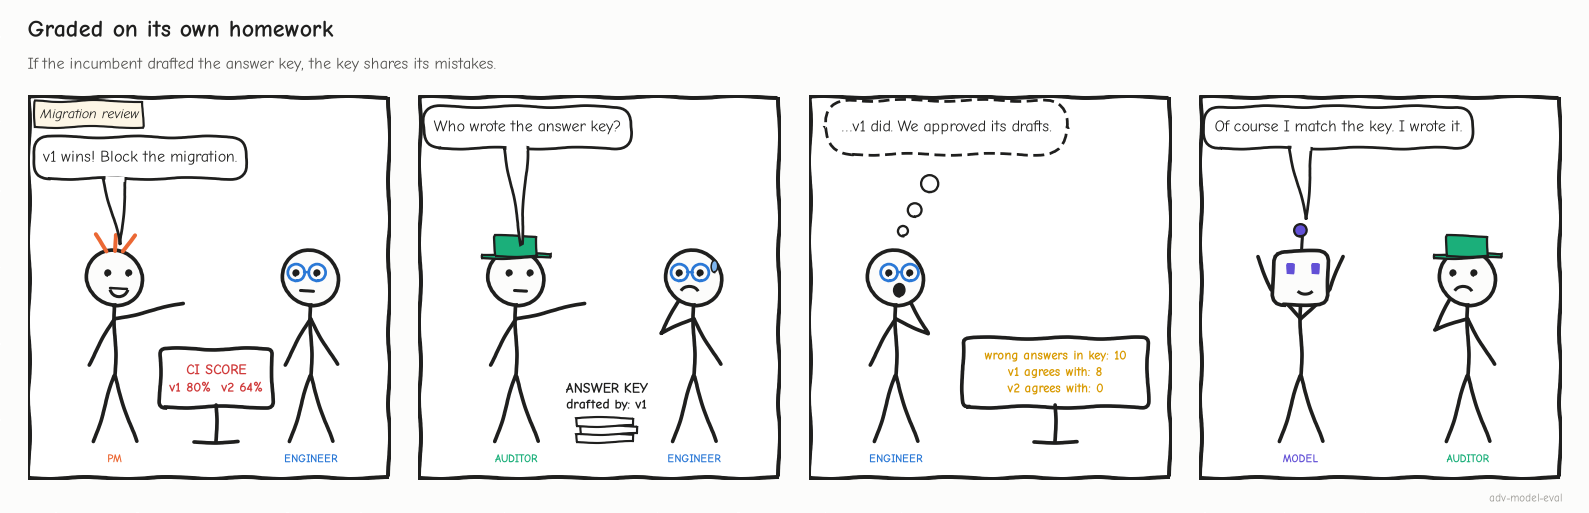

<sub>😄 *When the incumbent drafted the answer key, it agrees with the key's mistakes.*</sub>

<!-- img: gold-provenance.png -->
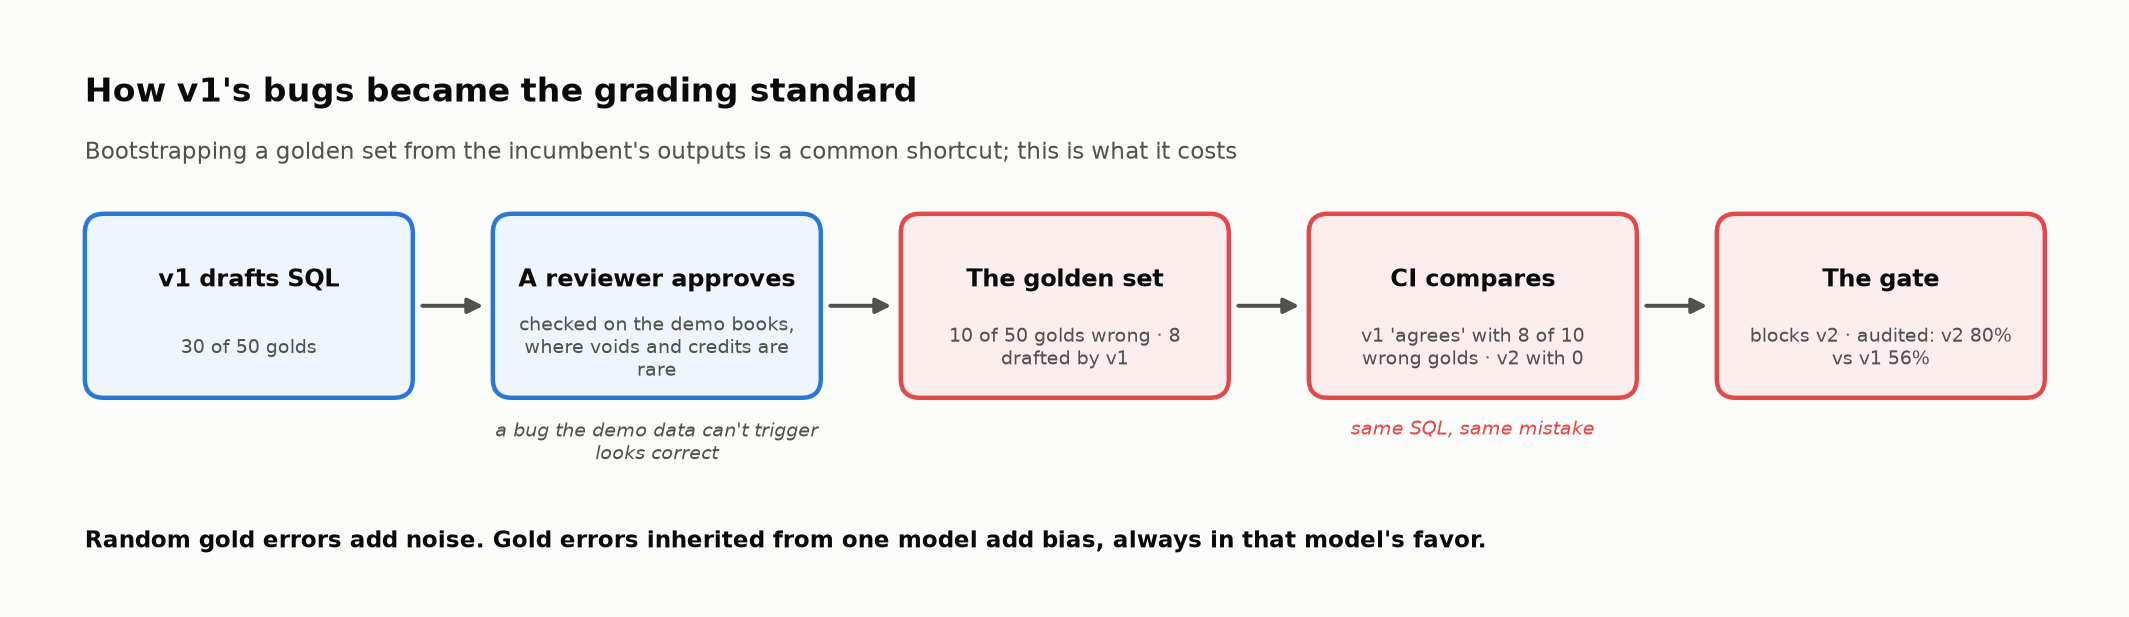

<sub>🖼️ *Each step is reasonable on its own. Together they turn v1's invisible bugs into the grading standard.*</sub>

🔍 **What just happened:** the reviewer approved v1's drafts on the demo books, where their bugs had no trigger, so each bug became part of the key.

🗣️ **Say it to a colleague:** "We let the incumbent write the answer key, then acted surprised when it aced the exam."

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** wrong golds: reviewer **2** of 20, v1 draft **8** of 30.

**Expected Output:** v1 reproduces **8 of 10**, v2 **0**; audited v1 → v2 **56% → 80%** (+24 pts).
</details>

In [ ]:
# @title ❓ Quick check: 10 of 50 golds are wrong. Why does that hurt the comparison more than 10 random typos would?
answer = "— pick one —"  # @param ["— pick one —", "A) It doesn't: 20% noise is 20% noise", "B) 8 of the 10 are v1's own drafts, so the errors reward v1 and fail whoever is right", "C) Wrong golds only break exact match", "D) The reviewer wrote most of them"]
quiz('Correlated gold errors', answer, correct="B",
     why="Random errors blur both models alike. These are v1's bugs, so v1 reproduces them and gets credit, and v2 gets failed for being right: a bias toward the incumbent.",
     wrong={"A": 'Random noise hurts both models alike. Here v1 reproduces 8 of the 10 and v2 none.',
          "C": 'They break every layer that compares with the gold: EX, the suite, CI.',
          "D": "The reviewer wrote 2; v1's approved drafts are 8."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Never let the model under test write the answer key; audit gold against a source that doesn't share its mistakes.</b></font>

</td></tr></table>

---

## Task 5: Questions With More Than One Right Answer

<big><b>An owner who asks about "contractors" and silently gets the Contract Labor account prepares 1099s from the wrong list.</b></big>

> 🎯 **Goal:** grade 10 ambiguous production questions three ways.<br>
> ❓ **The question:** which scoring rule rewards what owners need?<br>
> 👀 **Watch for:** answers that pick a reading without saying so.

> 📘 **Concept · Reading set**
>
> **What it is:** every interpretation (**reading**) of an ambiguous question that a careful bookkeeper would accept, each with its own SQL. An answer passes if its number matches **any** reading.
>
> **What it can't tell you:** whether the owner knows which reading they got. That takes a second check: does the answer **state its reading**, or ask?
>
> **Anchor:** *"How much did we spend on contractors last quarter?"* "Contractors" can mean the vendors you file **1099-NEC** forms for (self-employed people, in any expense account) or the **Contract Labor** account (which includes a staffing agency, a corporation that gets no 1099). Harbor & Pine's glossary settles accrual vs cash and calendar vs fiscal quarters; it never defined "contractors".

<!-- img: ambiguity-tree.png -->
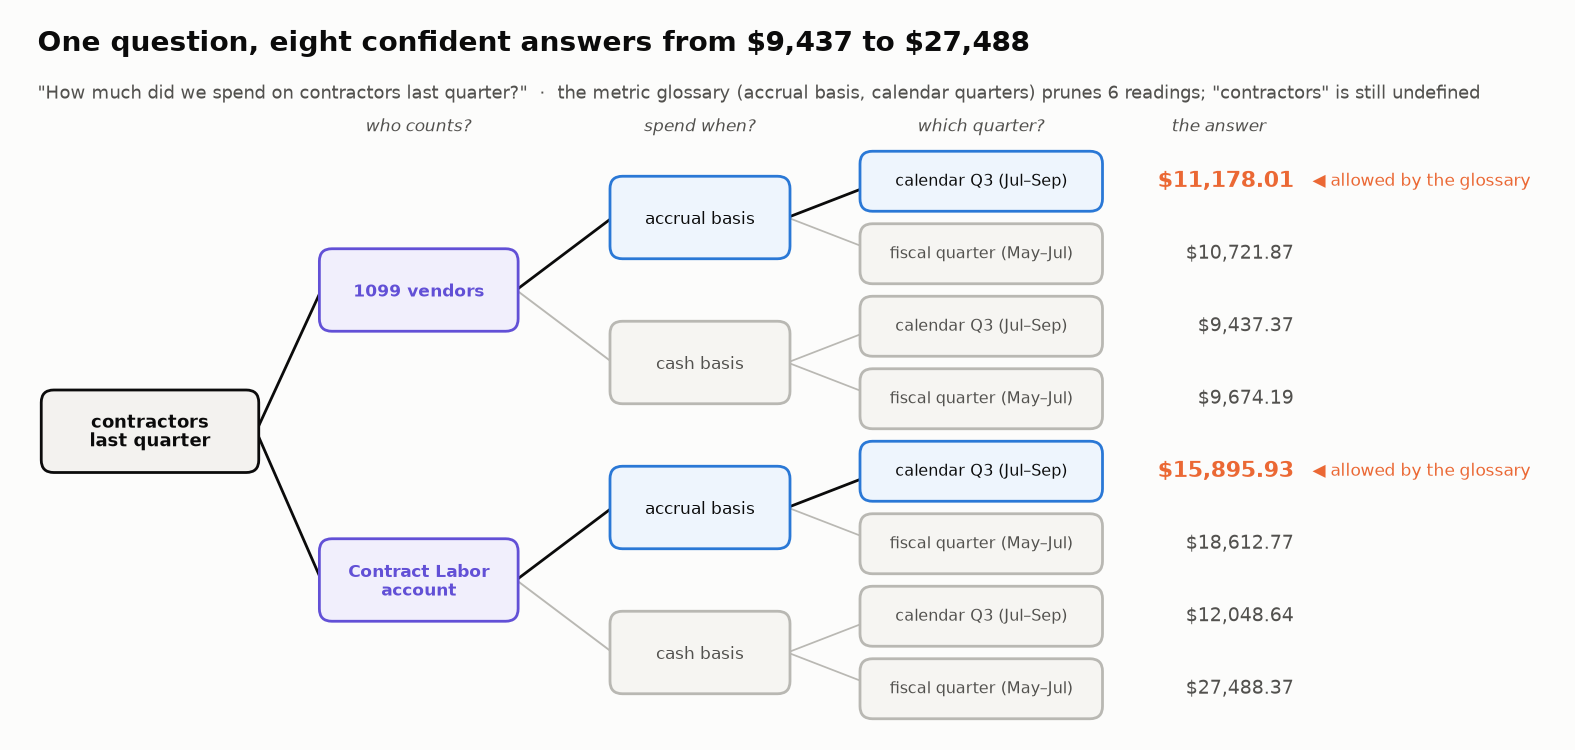

<sub>🖼️ *Every leaf is a number Ledgerly Ask could print with total confidence. Each split is a word the owner didn't define.*</sub>

| Rule | Pass if… | Problem |
|---|---|---|
| **Single gold** | the number matches the reviewer's one reading | grades which reading the model *guessed* |
| **Reading set** | the number matches *any* acceptable reading | can't see whether the owner knows which one |
| **Reading set + states it** | acceptable **and** the answer says which reading (or asks) | rewards what owners need |

▶️ **Run:** scores both models' answers by all three rules → compare *reading set* with *states its reading*.

In [ ]:
rows = []
for aid, (question, readings) in AMBIGUOUS.items():
    values = [run_sql(DEMO, sql)[0][0] for _, sql in readings]
    row = {"id": aid, "question": question, "readings": len(readings),
           "spread": max(values) / min(values) if min(values) else float("nan")}
    for m in MODELS:
        ans = ambiguous_answer(m, aid, DEMO)
        v = ans["value"]
        row[f"{m} answer"] = ans["text"]
        # 👀 Look at: three scoring rules for the same answer (reading 0 is the reviewer's single gold)
        row[f"{m} single gold"] = v is not None and abs(v - values[0]) <= 0.01
        row[f"{m} reading set"] = v is None or any(abs(v - x) <= 0.01 for x in values)   # a clarifying question is acceptable
        row[f"{m} states it"] = ans["states_assumption"]
    rows.append(row)
amb = pd.DataFrame(rows).set_index("id")
with pd.option_context("display.max_colwidth", 70):
    display(amb[["question", "v1 answer", "v2 answer"]].head(5))

amb_scores = pd.DataFrame({
    "single gold": [amb[f"{m} single gold"].sum() for m in MODELS],
    "reading set": [amb[f"{m} reading set"].sum() for m in MODELS],
    "states its reading": [amb[f"{m} states it"].sum() for m in MODELS],
    "reading set + states it": [(amb[f"{m} reading set"] & amb[f"{m} states it"]).sum() for m in MODELS],
}, index=MODELS)
display(amb_scores.rename(columns=lambda c: f"{c} (of {len(amb)})"))

▶️ **Run:** how far apart the readings are, and who says which one it used.

In [ ]:
# 💡 Reveal: how far apart are the readings, and who says which one it used?
plot_spreads(amb)
s = amb["spread"].sort_values()
big = int((amb["spread"] >= 1.25).sum())
silent = {m: int((~amb[f"{m} states it"]).sum()) for m in MODELS}
insight(
    f"Single-gold scoring ranks v2 {amb_scores.loc['v2', 'single gold']}/10 vs v1 {amb_scores.loc['v1', 'single gold']}/10. "
    f"That's a coin toss over readings: both models gave an acceptable reading every time",
    f"On {big} of 10 questions the readings differ by 25% or more (up to {s.max():.1f}×), so the reading matters more than the SQL. "
    f"The real difference is **silence**: v1 picks a reading without saying so on {silent['v1']} of 10 answers, v2 on "
    f"{silent['v2']}. An owner who reads v1's silent \"{amb.loc['A01', 'v1 answer']}\" for contractors can't tell it includes "
    "a staffing agency (a corporation, no 1099) and leaves out the plumber and the designer, who do get 1099s. "
    "Rule of thumb: **grade ambiguous questions against a set of readings, require the answer to state its reading "
    "(or ask), and shrink the ambiguity upstream by adding the term to the metric glossary.**",
)
insight(
    "Ambiguity, not SQL skill, explains much of the failure on ambiguous questions (AMBROSIA, NeurIPS 2024; ROSE, ACL 2026)",
    "AMBROSIA (Saparina & Lapata, NeurIPS 2024) built databases where questions have several valid SQL readings and found that "
    "even strong models struggle to notice the ambiguity; ROSE (Pei et al., ACL 2026) cites it for the finding that more than "
    "half of failures there arise from ambiguity, and argues execution accuracy against a single gold can't credit a different valid reading. "
    "Snowflake's 2024 write-up of Cortex Analyst's evaluation took the practical route: human reviewers accepted *several* gold queries per question.",
    kind="research",
)

✋ **Your turn:** silence only costs where the readings disagree. Find v2's dangerous silences.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_risky = amb.index[(~amb["v2 states it"]) & (amb["spread"] >= 1.25)]
_ref_risky = len(_risky)

In [ ]:
# ✋ Your turn: amb has one row per question, with a "spread" column (largest ÷ smallest reading)
#    and a True/False "v2 states it" column.
my_risky = ...   # ✏️ how many questions is v2 silent on AND the readings differ by 25% or more (spread >= 1.25)?

check("5A · v2's dangerous silences", my_risky, _ref_risky,
      hint="Combine two masks with &: ~amb['v2 states it'] and amb['spread'] >= 1.25, then .sum().",
      success=f"{_ref_risky} ({', '.join(_risky)}): silent answers whose readings differ by 25% or more. Those are the glossary entries to write first; a silent answer on a 1.00× question costs nothing on these books.")

🎛️ A07 and A10 measure 1.00× on the demo books. Pick other books: do they stay safe on `kitchen_sink`?

In [ ]:
# 🎛️ Re-measure each question's reading spread on another set of books.
BOOKS = "demo"  # @param ["demo", "void_and_draft", "last_day", "credits", "sibling_vendors", "no_vendor", "january_clock", "jitter", "kitchen_sink"]

for aid, (question, readings) in AMBIGUOUS.items():
    vals = [run_sql(SUITE[BOOKS], sql)[0][0] or 0 for _, sql in readings]
    spread = max(vals) / min(vals) if min(vals) else float("nan")
    print(f"{aid}  {spread:5.2f}×  {'⚠️' if spread >= 1.25 else '  '}  {question}")

🔍 **What just happened:** both models always picked an acceptable reading, so single gold only recorded whose guess matched the reviewer's. What differs is disclosure.

🗣️ **Say it to a colleague:** "On an ambiguous question, picking a reading isn't the bug. Not saying which one you picked is."

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** v1 / v2: single gold **5 / 6** · reading set **10 / 10** · states its reading **1 / 5**.

**Expected Output:** chart *"Readings of the same question differ by up to 4.0×"*.
</details>

In [ ]:
# @title ❓ Quick check: v1 answers the contractors question with a bare number that matches one valid reading. What's the bug?
answer = "— pick one —"  # @param ["— pick one —", "A) Nothing: the number matches an acceptable reading", "B) The SQL is wrong", "C) The owner can't tell which reading they got", "D) It should have refused to answer"]
quiz('The silent contractors answer', answer, correct="C",
     why='Its total includes a staffing agency (no 1099) and leaves out the plumber and the designer (who get 1099s). Stating the reading, or asking, is what makes the number usable.',
     wrong={"A": 'Acceptable to a grader; the owner may still file 1099s from the wrong list.',
          "B": "The SQL is right for its reading. That's why reading-set scoring passes it.",
          "D": 'Asking is fine, and so is answering with the reading stated. Refusing helps no one.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Grade ambiguous questions against a reading set, and require the answer to say which reading it used.</b></font>

</td></tr></table>

---

🧭 **Where you are:** Act 3 of 3 (Tasks 6–7): leave the golden set behind, then decide.

## Task 6: No Gold? Check Consistency Instead

<big><b>After launch there is no gold at all: without a gold-free check, the first person to spot a wrong number is the owner's accountant.</b></big>

> 🎯 **Goal:** catch wrong production answers with a relation the answers must satisfy.<br>
> ❓ **The question:** what can a consistency check catch, and what can't it see?<br>
> 👀 **Watch for:** a model that's wrong on every answer and passes anyway.

> 📘 **Concept · Metamorphic relation**
>
> **What it is:** a rule connecting several answers, so that a violation proves at least one of them is wrong, with no gold. "Spend on Packaging in Q2 = April + May + June" is one. Ask the related questions, check the rule; it runs on live traffic.
>
> **What it can't tell you:** which of the answers is wrong, or anything about a mistake that shifts all the related answers consistently. Consistent isn't correct.
>
> **Anchor:** if the model says Packaging's Q2 is ＄3,185.84 and its three months sum to ＄3,032.04, one of those four answers is wrong, and you know it without knowing the right number.

✋ **Your turn:** **Exercise 6A**, the relation's core line: a quarter must equal the sum of its three months.

In [ ]:
# @title 🧰 Reference answer + 5 test cases for Exercise 6A (hidden · spoiler)
decomposition_gap = _reference_decomposition_gap   # the lab keeps going with the reference check


def value_of(rows):
    """The single number in a result, or None for an error, no rows, or NULL."""
    if isinstance(rows, str) or not rows or rows[0][0] is None:
        return None
    return float(rows[0][0])


_CASES_6A = [
    ([(300.0,)], [[(100.0,)], [(100.0,)], [(100.0,)]]),              # holds
    ([(300.0,)], [[(100.0,)], [(100.0,)], [(99.995,)]]),             # within a cent
    ([(300.0,)], [[(100.0,)], [(80.0,)], [(100.0,)]]),               # a $20 violation
    ([(300.0,)], [[(100.0,)], "ERROR: no such table", [(100.0,)]]),  # a broken answer
    ([(None,)], [[(1.0,)], [(1.0,)], [(1.0,)]]),                      # a NULL total
]
_ref_6A = [_reference_decomposition_gap(qr, ms) for qr, ms in _CASES_6A]


def _grade_6A(fn):
    """`...` while the blank is open; otherwise your gaps on the five test cases."""
    try:
        got = [fn(qr, ms) for qr, ms in _CASES_6A]
    except Exception as e:  # noqa: BLE001
        return f"an error: {type(e).__name__}: {e}"
    return ... if any(todo(g) for g in got) else got

In [ ]:
# ✋ Your turn (Exercise 6A): the metamorphic relation "a quarter = the sum of its three months".
def my_decomposition_gap(quarter_rows, month_rows_list, tol=0.01):
    q, months = value_of(quarter_rows), [value_of(r) for r in month_rows_list]   # None: error, empty or NULL
    if q is None or None in months:
        return float("inf")                     # a broken answer is a violation
    return ...   # ✏️ the violation in dollars: 0.0 if the quarter equals its months' sum within tol, else the gap

check("6A · Quarter = sum of its months", _grade_6A(my_decomposition_gap), _ref_6A,
      hint="The gap is |quarter − (m1 + m2 + m3)|. Report 0.0 when it is within tol: a cent of rounding is not a bug.",
      success="5 of 5, including the half-cent case and the broken answer. The relation needs no gold, so it can run on live traffic.")

In [ ]:
# @title 🔮 Predict: v2 answers 24 families (a quarter and its 3 months); about 1 answer in 9 is wrong. What share of the wrong answers will the relation catch?
relation_catches_will_be = "— pick one —"  # @param ["— pick one —", "A) Under 25%", "B) Over 75%", "C) 25 to 75%"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** v2 answers the 24 families on a real customer's messier books → read the last tile, then your prediction.

In [ ]:
prod_books = make_production_books()

def run_families(sql_for):
    out = []
    for f in production_families():
        qs = [("account_spend", (f["account"], f["quarter"]))] + [("account_spend", (f["account"], mm)) for mm in f["months"]]
        res = [run_sql(prod_books, sql_for(t, a)) for t, a in qs]
        wrong = [not results_match(r, run_sql(prod_books, write_sql(t, a))) for r, (t, a) in zip(res, qs)]  # truth: only a simulation can see this
        # 👀 Look at: the flag (gap $) needs no gold; 'wrong answers' is the truth only a simulation can see
        out.append({"family": f"{f['account']} {f['quarter']}", "gap $": decomposition_gap(res[0], res[1:]),
                    "wrong answers": sum(wrong)})
    return pd.DataFrame(out).set_index("family")

fam = run_families(lambda t, a: v2_sql_for(t, a)[0])
flagged = fam["gap $"] > 0
n_wrong = int(fam["wrong answers"].sum())
caught = int(fam.loc[flagged, "wrong answers"].sum())
tiles([
    ("Production questions answered", 4 * len(fam), f"{len(fam)} families of 4", None),
    ("Wrong answers (truth)", n_wrong, f"{pct(n_wrong / (4 * len(fam)))} of answers; unknown in real life", "serious"),
    ("Families flagged", f"{flagged.sum()} of {len(fam)}", "no gold needed", "warning"),
    ("Wrong answers inside flagged families", f"{caught} of {n_wrong}", "found with zero labels", "good"),
])
display(fam[flagged].round(2))
quiz("Your prediction: what the relation catches", relation_catches_will_be,
     correct="B" if caught > 0.75 * n_wrong else "A" if caught < 0.25 * n_wrong else "C",
     why=f"{caught} of {n_wrong}, with zero labels: v2's slips hit one or two answers in a family, so the parts stop adding up.")

✋ **Your turn:** predict in code. Now give the model one *habit* on every row: it adds vendor credits instead of subtracting them.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_habit_flags = int((run_families(lambda t, a: write_sql(t, a, "CREDIT", "v2"))["gap $"] > 0).sum())

In [ ]:
# ✋ Your turn: with the credit habit, every one of the 96 production answers is wrong.
my_habit_flags = ...   # ✏️ how many of the 24 families will the relation flag?

check("6B · Flags for an every-row habit", my_habit_flags, _ref_habit_flags,
      hint="A quarter's credits are exactly its three months' credits. Adding them shifts the quarter by the same amount as the sum of the months.",
      success=f"{_ref_habit_flags} of 24: the quarter and its months move by exactly the same amount, so the relation holds while every answer is wrong.")

▶️ **Run:** the blind spot, revealed.

In [ ]:
# 🔎 The blind spot: the same model, but with ONE systematic habit (it always adds vendor credits instead of subtracting)
fam_sys = run_families(lambda t, a: write_sql(t, a, "CREDIT", "v2"))
sys_wrong, sys_flagged = int(fam_sys["wrong answers"].sum()), int((fam_sys["gap $"] > 0).sum())
print(f"Systematic bug: {sys_wrong} of {4 * len(fam_sys)} answers wrong, {sys_flagged} of {len(fam_sys)} families flagged.")
insight(
    f"Consistency checks caught all {caught} of v2's {n_wrong} wrong production answers without a single gold, "
    f"and caught 0 of {sys_wrong} when the same bug appeared everywhere",
    f"v2's slips are **sporadic**: one month query drops the last day, another counts a voided entry, so the parts stop "
    f"adding up and {flagged.sum()} families light up. A habit applied to **every row** (here: adding credits) moves the "
    "quarter by exactly what it moves the months, and the relation holds perfectly. That's the division of labor: metamorphic checks watch production for slips, "
    "fuzzed test suites catch row-level habits before release. Rule of thumb: **run cheap relations on live traffic "
    "(parts sum to the whole, paraphrases agree), and never read 'consistent' as 'correct'.**",
    kind="production",
)

<!-- img: metamorphic-blind-spot.png -->
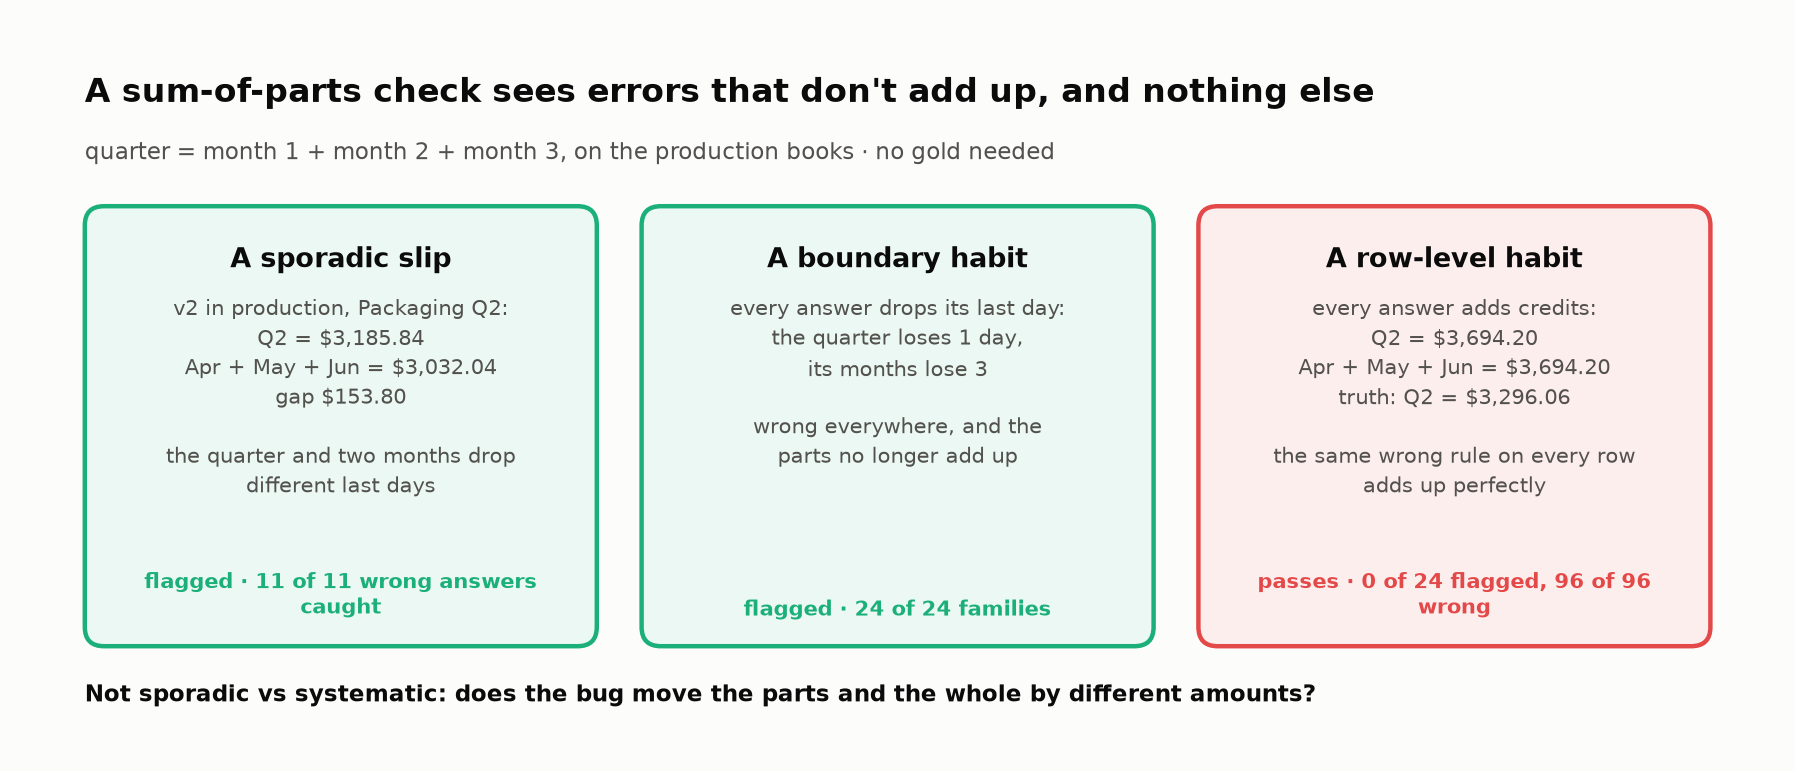

<sub>🖼️ *One relation, three bugs. It sees the two that move the quarter and the sum of its months by different amounts.*</sub>

🔍 **What just happened:** the test is whether a bug moves the whole and its parts by *different* amounts, which is why a systematic last-day bug (the quarter loses one day, its months three) *is* caught.

🗣️ **Say it to a colleague:** "A consistency check catches errors that don't add up. A habit that's wrong on every row adds up fine."

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** **11** of 96 wrong; **8 of 24** families flagged, holding **11 of 11** wrong answers.

**Expected Output:** `Systematic bug: 96 of 96 answers wrong, 0 of 24 families flagged.`
</details>

🎛️ Use the diagram's rule to predict each habit's flag count, then pick it: `VOID`, `DOUBLE`, `BOUNDARY`.

In [ ]:
# 🎛️ Other every-row habits, same relation.
HABIT = "CREDIT"  # @param ["CREDIT", "VOID", "DOUBLE", "BOUNDARY"]

fam_try = run_families(lambda t, a: write_sql(t, a, HABIT, "v2"))
print(f"{HABIT} ({_BUG_NOTES[HABIT]}): {int(fam_try['wrong answers'].sum())} of {4 * len(fam_try)} answers wrong, "
      f"{int((fam_try['gap $'] > 0).sum())} of {len(fam_try)} families flagged")

In [ ]:
# @title ❓ Quick check: this week the monitor flags 0 of 24 families. What can you conclude?
answer = "— pick one —"  # @param ["— pick one —", "A) v2 is right on every production answer", "B) The monitor is broken: it should always flag something", "C) Next week's traffic will surface any habit", "D) No sporadic slip broke a relation; an every-row habit could still be live"]
quiz('Zero flags', answer, correct="D",
     why="The credit habit was wrong on 96 of 96 answers and flagged 0 families. Relations watch for slips; the fuzzed suite (and Challenge 5's probes) catch habits before release.",
     wrong={"A": "Consistent isn't correct: the credit habit passes every family.",
          "B": 'Zero flags is what a clean week looks like, and also what an every-row habit looks like.',
          "C": 'An every-row habit adds up every week.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Consistent is not correct: relations catch slips that don't add up, never a habit applied to every row.</b></font>

</td></tr></table>

---

## Task 7: The Migration Decision

<big><b>v1 retires on 14 January: "block" means asking for an extension that may not come.</b></big>

> 🎯 **Goal:** put every layer on one chart, compare the models question by question, and make the call.<br>
> ❓ **The question:** is v2's lead real, or noise on 50 questions?<br>
> 👀 **Watch for:** how few questions the verdict rests on.

> 💡 **Key idea:** on the same 50 questions only **discordant pairs** vote: v2 right and v1 wrong (*fixed*), or the reverse (*broke*). The exact **McNemar test** asks how surprising the split is if each were a coin flip. A **Wilson interval** on 50 questions is about ±11 points.

In [ ]:
# @title 🔮 Predict: on the audited verdicts, how many questions did v2 fix (v1 wrong, v2 right) vs break?
fixed_vs_broke_will_be = "— pick one —"  # @param ["— pick one —", "A) v2 ahead by 10 or more", "B) About even", "C) v2 ahead by 2 to 6"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** the five-layer ladder, v2's remaining failures, the paired test, and your prediction graded.

In [ ]:
LADDER = ["Exact match", "CI (strict EX)", "EX (one DB)", "Test suite", "Audited (vs truth)"]
ladder = pd.DataFrame({L: {m: 100 * layers[L][m].mean() for m in MODELS} for L in LADDER}).T
plot_ladder(ladder)

# 👀 Look at: only the questions the models DISAGREE on (fixed vs broke) enter the paired test
fixed = int((aud["v2"] & ~aud["v1"]).sum())
broke = int((aud["v1"] & ~aud["v2"]).sum())
p_mc = mcnemar_exact_p(fixed, broke)
ci_v = {m: wilson_ci(int(aud[m].sum()), len(golden)) for m in MODELS}
v2_fail = [q for q in golden.index if not aud["v2"][q]]
display(pd.DataFrame({"question": golden.question[v2_fail].str[:55], "what v2 got wrong": [auditor_note(q, "v2") for q in v2_fail]}))
tiles([
    ("v2 fixed", fixed, "v1 wrong → v2 right", "good"),
    ("v2 broke", broke, "v1 right → v2 wrong", "warning"),
    ("McNemar p", f"{p_mc:.3f}", "< 0.05: unlikely to be chance", "good" if p_mc < 0.05 else "warning"),
    ("v2 audited (95% CI)", pct(aud["v2"].mean()), f"{pct(ci_v['v2'][0])}–{pct(ci_v['v2'][1])}", None),
])
quiz("Your prediction: fixed vs broke", fixed_vs_broke_will_be,
     correct="A" if fixed - broke >= 10 else "C" if fixed - broke >= 2 else "B",
     why=f"Fixed {fixed}, broke {broke}. The other {len(golden) - fixed - broke} questions got the same verdict from both models and say nothing about which is better.")

<!-- img: discordant-pairs.png -->
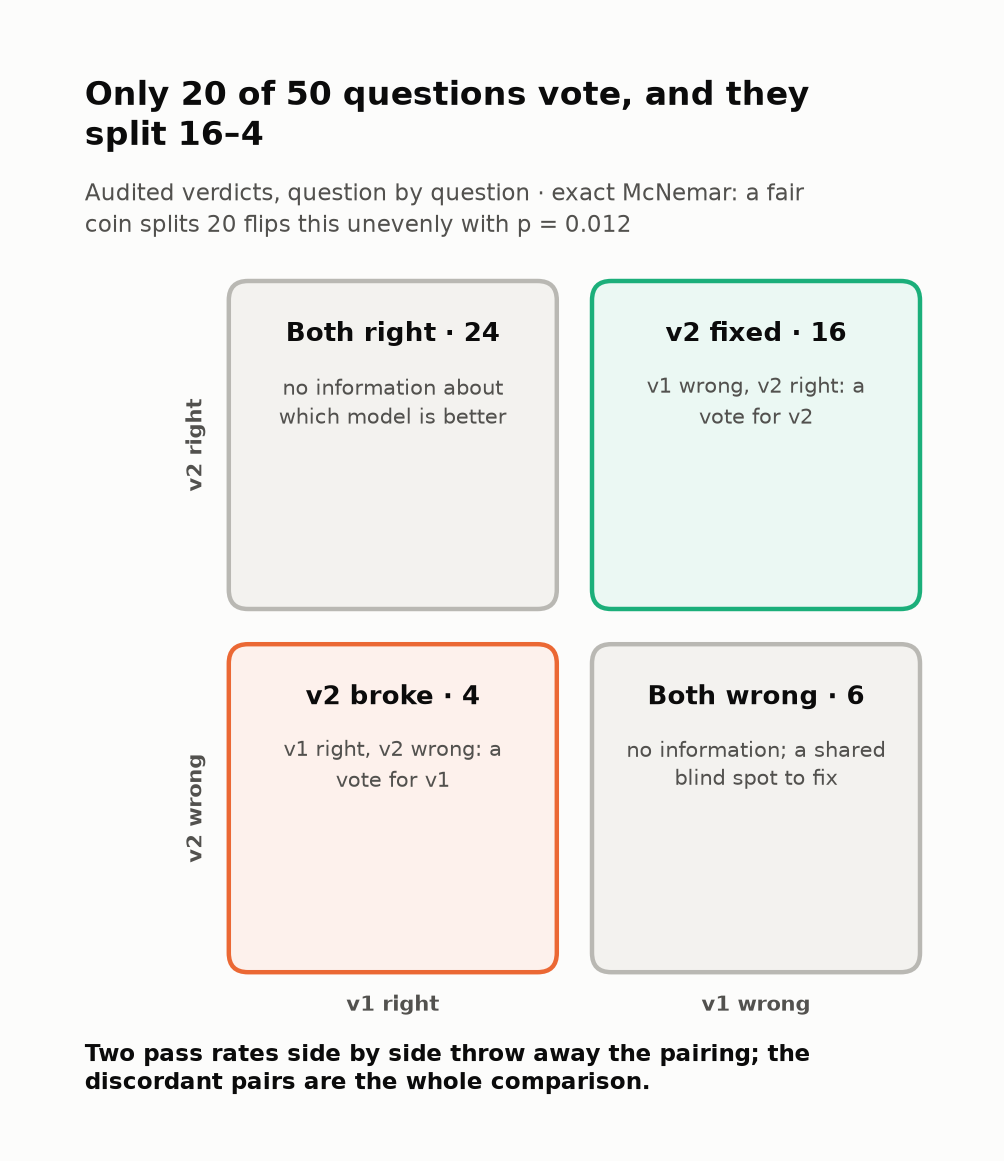

<sub>🖼️ *The 30 questions both models agree on say nothing about which is better; the decision rests on the other 20.*</sub>

🎛️ Move questions from *fixed* to *broke* and watch the paired test. How many must switch sides before chance can explain the split?

In [ ]:
# 🎛️ Defaults reproduce the tiles above.
FLIPS = 0  # @param {type:"slider", min:0, max:6, step:1}

f_, b_ = fixed - FLIPS, broke + FLIPS
p_try = mcnemar_exact_p(f_, b_)
print(f"fixed {f_}, broke {b_}  →  McNemar p = {p_try:.3f}  " + ("(significant at 0.05)" if p_try < 0.05 else "(could be chance)"))

✋ **Your turn:** record what the slider showed.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_flips = next(k for k in range(fixed + 1) if mcnemar_exact_p(fixed - k, broke + k) >= 0.05)

In [ ]:
# ✋ Your turn: the smallest number of questions that, moving from "fixed" to "broke", makes p >= 0.05.
my_flips = ...   # ✏️ a whole number

check("7A · How many answers the verdict rests on", my_flips, _ref_flips,
      hint="Drag FLIPS up one step at a time and re-run the slider cell; stop at the first p of 0.05 or more.",
      success=f"{_ref_flips}: p goes from {p_mc:.3f} to {mcnemar_exact_p(fixed - _ref_flips, broke + _ref_flips):.3f}. On 50 questions a verdict rests on a handful of answers, so audit those answers first.")

✋ **Your turn:** make the call before the code does.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_v2_better = aud["v2"].mean() > aud["v1"].mean() and p_mc < 0.05
_disclosure = amb_scores.loc["v2", "states its reading"] / len(amb)
_ref_call = "SHIP" if _v2_better and _disclosure >= 0.8 else "SHIP WITH CAUTION" if _v2_better else "BLOCK"

In [ ]:
# ✋ Your turn: the evidence on one line. CI's gate (block if v2 trails by more than 2 points) says BLOCK.
print(f"audited: v2 {pct(aud['v2'].mean())} vs v1 {pct(aud['v1'].mean())} · fixed {fixed}, broke {broke} (p = {p_mc:.3f}) · "
      f"v2 states its reading on {amb_scores.loc['v2', 'states its reading']} of {len(amb)} ambiguous questions")

my_call = ...   # ✏️ "SHIP", "SHIP WITH CAUTION" or "BLOCK"

check("7B · The migration call", my_call, _ref_call,
      hint="CI measured the wrong thing. Is v2 better on audited, paired evidence? Then: are owners told which reading they got?",
      success=f"{_ref_call}: v2 is better (p = {p_mc:.3f}), but it states its reading on only {amb_scores.loc['v2', 'states its reading']} of {len(amb)} ambiguous questions. The verdict below writes the guards in.")

▶️ **Run:** the verdict, with its five reasons.

In [ ]:
GATE = -0.02                       # CI's rule: block if v2 is more than 2 points worse than v1
v2_better = aud["v2"].mean() > aud["v1"].mean() and p_mc < 0.05
disclosure = amb_scores.loc["v2", "states its reading"] / len(amb)
monitor_ok = caught == n_wrong

# 👀 Look at: SHIP needs better audited, paired evidence AND an owner who's told which reading they got
if v2_better and disclosure >= 0.8:
    decision = "SHIP"
elif v2_better:
    decision = "SHIP WITH CAUTION"
else:
    decision = "BLOCK"

reasons = [
    f"**v2 is better, not worse:** {pct(aud['v2'].mean())} vs {pct(aud['v1'].mean())} against the audited truth "
    f"(v2 fixed {fixed}, broke {broke}; McNemar p = {p_mc:.3f}). CI's {signed(100 * gap_ci)} pts came from text style, "
    f"float noise, and an answer key v1 drafted.",
    f"**Fix the eval before the next gate:** correct the {n_bad} wrong golds, switch CI to `results_match` on the "
    f"{len(SUITE)}-database suite, and stop seeding golds from the model under test.",
    f"**Ship with guards for v2's known slips** ({len(v2_fail)} audited failures: "
    + ", ".join(f"{n}× {note}" for note, n in pd.Series([auditor_note(q, "v2") for q in v2_fail]).value_counts().items())
    + "): add a SQL lint that flags spend queries without `status = 'posted'` or with `bill_payment`/`payment` in the type list.",
    f"**Before GA, make v2 state its reading:** it does so on {amb_scores.loc['v2', 'states its reading']} of {len(amb)} "
    "ambiguous questions; add 'contractors', 'this year' and 'pay' to the metric glossary.",
    f"**Watch production:** the metamorphic monitor caught {caught} of {n_wrong} sporadic errors offline; run it on live traffic.",
]
verdict(decision, reasons)

🔍 **What just happened:** the gap flips sign only at the audit, and the paired test says the flip isn't noise.

🗣️ **Say it to a colleague:** "Only the questions where the models disagree get a vote, and v2 won them 16 to 4."

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** ladder v1 68 → 80 → 80 → 68 → 56; v2 6 → 64 → 74 → 60 → 80.

**Expected Output:** fixed **16**, broke **4**, p **0.012**; banner ⚠️ **SHIP WITH CAUTION**.
</details>

✍️ **Your call** (double-click to edit): two sentences to the PM, and the one chart for the launch doc.

In [ ]:
# @title ❓ Quick check: 30 of the 50 questions got the same audited verdict from both models. What do they say about which is better?
answer = "— pick one —"  # @param ["— pick one —", "A) Nothing: only the 20 discordant questions vote", "B) They are the strongest evidence, because both models agree", "C) They make the 24-point gap significant"]
quiz('The agreeing questions', answer, correct="A",
     why='Both right or both wrong is the same outcome for either model. The paired test runs on the 16 fixed and 4 broke.',
     wrong={"B": 'Agreement says the question is easy (or hard) for both, not which model is better.',
          "C": "Add 100 more questions both models get right and the McNemar p doesn't move."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Decide on paired, audited evidence: only the questions the models disagree on get a vote.</b></font>

</td></tr></table>

---

## 🔌 Optional: Let a Real Model Write the SQL

A model writes SQL for five golden questions from the schema and glossary; each query is graded on the audited suite. `PROVIDER = "mock"` (default) replays v2's SQL; `"openai"` / `"anthropic"` need `OPENAI_API_KEY` / `ANTHROPIC_API_KEY` in Colab 🔑 Secrets.

▶️ **Run** the next two cells: 🧰 provider plumbing (hidden), then ⚙️ CONFIG → one ✅/❌ per question.

In [ ]:
# @title 🧰 Provider plumbing: the structured-output schema, the prompt, and the OpenAI / Anthropic / mock calls (hidden · 37 lines · expand if you'll use a real key)
import os

from pydantic import BaseModel, Field


class SQLAnswer(BaseModel):
    assumptions: str = Field(description="Any reading you chose for an ambiguous term, in one sentence; empty if none")
    sql: str = Field(description="One SQLite SELECT statement that answers the question")


SYSTEM = (f"You write SQLite for a small business's books. Schema:\n{SCHEMA_DOC}\n\n{GLOSSARY}\n"
          "Today's date is in company.as_of. Return one SELECT statement.")


def _get_secret(name):
    try:
        from google.colab import userdata  # type: ignore
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)


def generate_sql(qid):
    question = golden.question[qid]
    if PROVIDER == "openai":
        from openai import OpenAI
        resp = OpenAI(api_key=_get_secret("OPENAI_API_KEY")).responses.parse(
            model=OPENAI_MODEL, instructions=SYSTEM, input=question, text_format=SQLAnswer)
        return resp.output_parsed
    if PROVIDER == "anthropic":
        import anthropic
        resp = anthropic.Anthropic(api_key=_get_secret("ANTHROPIC_API_KEY")).messages.parse(
            model=ANTHROPIC_MODEL, max_tokens=1024, system=SYSTEM,
            messages=[{"role": "user", "content": question}], output_format=SQLAnswer)
        return resp.parsed_output
    return SQLAnswer(assumptions="", sql=RECORDED["v2"][qid])

In [ ]:
# ⚙️ CONFIG — model IDs live only in this cell
PROVIDER = "mock"                      # "mock" | "openai" | "anthropic"
OPENAI_MODEL = "gpt-6-luna"
ANTHROPIC_MODEL = "claude-haiku-5-5"

if PROVIDER != "mock" and not _get_secret(f"{PROVIDER.upper()}_API_KEY"):
    print(f"⚠️  No {PROVIDER.upper()}_API_KEY found. Falling back to PROVIDER = 'mock'.")
    PROVIDER = "mock"

# 👀 Look at: a real model's SQL is graded on all 9 suite databases against the audited truth
for qid in ["G08", "G23", "G33", "G35", "G38"]:
    ans = generate_sql(qid)
    ok = all(results_match(run_sql(con, ans.sql), truth_suite[qid][db], golden.ordered[qid]) for db, con in SUITE.items())
    print(f"{qid} {'✅' if ok else '❌'}  {golden.question[qid][:58]:<58}" + (f"  [{ans.assumptions}]" if ans.assumptions else ""))
print(f"\nSQL written by: {PROVIDER}" + ("" if PROVIDER == "mock" else f" ({OPENAI_MODEL if PROVIDER == 'openai' else ANTHROPIC_MODEL})"))

**Expected Output** (mock): five ✅ lines, then `SQL written by: mock`. With a real model, read every ❌: run its query on `SUITE["demo"]` and on the database that breaks it.

---

## ✅ Validation or Success Criteria

<details><summary>Check yourself</summary>

- [ ] You can say what exact match, the comparator, the suite and the audit each changed
- [ ] You can name the bug a metamorphic relation can't see
- [ ] `scoreboard()` is green, or you know why not
</details>

▶️ **Run:** the self-test → expect `✅ All checks passed`.

In [ ]:
# SELF-TEST: the lab's key invariants
assert (ci["v1"].sum(), ci["v2"].sum()) == (40, 32), "CI scores"
assert (em["v1"].sum(), em["v2"].sum()) == (34, 3), "exact match"
assert (ex["v1"].sum(), ex["v2"].sum()) == (40, 37), "comparator"
assert ts["v1"].sum() < ex["v1"].sum() and ts["v2"].sum() < ex["v2"].sum(), "the suite removes passes"
assert (n_bad, n_bad_v1) == (10, 8) and agrees_with_gold["v1"][bad].sum() == 8, "gold audit"
assert (aud["v1"].sum(), aud["v2"].sum()) == (28, 40), "audited scores"
assert (fixed, broke) == (16, 4) and p_mc < 0.05, "paired test"
assert caught == n_wrong and sys_flagged == 0, "metamorphic checks"
assert decision == "SHIP WITH CAUTION"
print("✅ All checks passed")

## 🔧 Troubleshooting

<details><summary>Common problems</summary>

| Symptom | Fix |
|---|---|
| `NameError` | **Runtime → Run all** (the 🧰 catch-up rebuilds Part 1) |
| ⏳ on an exercise | Replace the `...` and re-run the cell |
| Challenge 4 corners don't match −16 / +24 | Scale by 100 / 50; require a match on *every* database |
| Challenge 5 alarms on v2's correct SQL | A probe's expected change is wrong: re-read the glossary |
| Real-provider cell errors | Add the key to 🔑 Secrets, or keep `PROVIDER = "mock"` |
</details>

## 🧩 Stretch Goal or Extension

- **A · Your own books:** five questions, your gold SQL, one fuzzer for an edge case *your* data has.
- **B · Paraphrase invariance:** treat `v2_sql_for(…, seed=…)` seeds as phrasings; how many disagree on `prod_books`?
- **C · A glossary entry** that removes A01's "contractors" ambiguity.

### 🏆 Challenge exercises

Each starter runs as shipped and prints ✅/❌; worked solutions are in the instructor guide.

#### 🌶️ Challenge 1: Distill the suite

**Stakes:** every database in the suite multiplies CI time on every model and prompt change, and a suite too slow to run on every change gets skipped.

Find the **smallest** set of suite databases that reproduces all 100 audited verdicts. If one is enough, why keep the single-purpose ones?

<details><summary>💡 Hint</summary>

Greedy set cover from `["demo"]`: add the database that fixes the most verdicts until all match `full`. Then: what does a failure on `kitchen_sink` tell you that one on `credits` does?
</details>

▶️ **Run:** the starter.

In [ ]:
# 🏆 Challenge 1 starter (runs as shipped)
full = {(m, q): passes_everywhere(m, q, truth_suite) for m in MODELS for q in golden.index}

def verdicts_with(dbs):
    return {(m, q): all(results_match(pred_suite[m][q][db], truth_suite[q][db], golden.ordered[q]) for db in dbs)
            for m in MODELS for q in golden.index}

def distill(candidates):
    # TODO: greedy set cover (see the hint). Return a short list of database names.
    return list(candidates)          # placeholder: the whole suite

chosen = distill(list(SUITE))
same = verdicts_with(chosen) == full
print(f"{'✅' if same and len(chosen) <= 2 else '❌'} {len(chosen)} database(s) {chosen} reproduce "
      f"{'all' if same else 'NOT all'} {len(full)} verdicts" + ("" if len(chosen) <= 2 else "  (target: ≤ 2)"))

#### 🌶️🌶️ Challenge 2: Break the metric, then fix the suite

**Stakes:** a team that reads 100% test-suite accuracy as "correct" ships the one query whose trigger isn't in any of its databases.

For **G26** (Verde Importers, July 2026), write `adversarial_sql`: right on all 9 suite databases, wrong in general. Then `adversary_fuzzer`, which exposes it. What does that say about choosing fuzzers?

<details><summary>💡 Hint</summary>

Add a condition to `_TRUTH_SQL["G26"]` that every Verde row in the suite happens to meet (look at the amounts); the fuzzer inserts one realistic row that breaks it.
</details>

▶️ **Run:** the starter.

In [ ]:
# 🏆 Challenge 2 starter (runs as shipped)
TARGET = "G26"
adversarial_sql = None               # TODO: a string of SQL

def adversary_fuzzer(con, rng):
    pass                             # TODO: insert the row(s) that expose adversarial_sql

if adversarial_sql is None:
    print("📝 Challenge 2: write adversarial_sql and adversary_fuzzer, then re-run this cell.")
else:
    passes = all(results_match(run_sql(con, adversarial_sql), truth_suite[TARGET][db]) for db, con in SUITE.items())
    probe = clone_db(DEMO)
    adversary_fuzzer(probe, random.Random(0))
    exposed = not results_match(run_sql(probe, adversarial_sql), report_engine(TARGET, probe))
    print(f"{'✅' if passes else '❌'} passes all {len(SUITE)} suite databases")
    print(f"{'✅' if exposed else '❌'} your fuzzer exposes it")

#### 🌶️🌶️🌶️ Challenge 3: How wrong is production, with no gold?

**Stakes:** the launch review will ask how often Ledgerly Ask is wrong in production, and there are no labels to answer with.

Estimate v2's **per-answer** error rate from the share of flagged families and check it against the simulated truth. Which two assumptions does it rest on, and which way does each bias it?

<details><summary>💡 Hint</summary>

With k = 4 answers each wrong independently with probability e, P(flagged) = 1 − (1 − e)^k. Then think of Task 6's blind spot, and two errors that cancel.
</details>

▶️ **Run:** the starter.

In [ ]:
# 🏆 Challenge 3 starter (runs as shipped). 5 re-asks of every family = 120 families, 480 answers.
many = pd.concat([run_families(lambda t, a, s=s: v2_sql_for(t, a, seed=s)[0]) for s in range(5)])
flag_rate = float((many["gap $"] > 0).mean())
true_rate = many["wrong answers"].sum() / (4 * len(many))     # hidden in real life

def estimate_error_rate(flag_rate, k=4):
    # TODO: invert P(flagged) = 1 - (1 - e)**k
    raise NotImplementedError

try:
    est = estimate_error_rate(flag_rate)
    ok = abs(est - true_rate) <= 0.03
    print(f"{'✅' if ok else '❌'} flagged {pct(flag_rate)} of families → estimated error rate {pct(est, 1)}; truth {pct(true_rate, 1)}")
except NotImplementedError:
    print(f"📝 Challenge 3: flagged {pct(flag_rate)} of {len(many)} families. Implement estimate_error_rate, then re-run.")

#### 🌶️🌶️ Challenge 4: One afternoon before the gate

**Stakes:** the gate meeting is Friday and there's time to fix one thing in the eval. Fix the wrong one and you walk in with a more rigorous-sounding number that points the wrong way.

Three fixes (**comparator**, **databases**, **answer key**) make 8 ways to grade the same SQL. 🔮 Which *single* fix moves CI's −16 furthest toward +24, and which moves it the wrong way? Finish `gap_pts()`, then set `ONE_FIX` to the only single fix that clears the −2-point gate.

<details><summary>💡 Hint</summary>

A model passes `q` when `comparator(pred_suite[m][q][db], key[q][db], golden.ordered[q])` holds for every `db` in `dbs`; return `100 * (v2 − v1) / len(golden)`. For "suite": strict `==` meets v2's unrounded totals nine times.
</details>

▶️ **Run:** the starter.

In [ ]:
# 🌶️🌶️ Challenge 4 starter: runs as shipped; finish gap_pts, then set ONE_FIX
SWITCHES = {"comparator": (strict_match, results_match),          # (before the fix, after the fix)
            "suite":      (["demo"], list(SUITE)),
            "key":        (gold_suite, truth_suite)}


def gap_pts(comparator, dbs, key):
    """TODO: v2's pass rate minus v1's, in points. A question passes if comparator(prediction, key) holds on every db."""
    return 0.0                                                     # placeholder


rows = []
for on in itertools.product([False, True], repeat=3):
    label = " + ".join(name for name, flag in zip(SWITCHES, on) if flag) or "none (CI today)"
    rows.append((label, gap_pts(*[SWITCHES[name][flag] for name, flag in zip(SWITCHES, on)])))
grid = pd.DataFrame(rows, columns=["fixes applied", "v2 − v1 (pts)"]).set_index("fixes applied")
display(grid.round(0))

ONE_FIX = None                                                     # TODO: "comparator", "suite" or "key"
single, corners = grid["v2 − v1 (pts)"][list(SWITCHES)], (100 * gap_ci, 100 * (aud["v2"].mean() - aud["v1"].mean()))
print("✅" if (round(grid.iloc[0, 0]), round(grid.iloc[-1, 0])) == tuple(map(round, corners)) else "❌",
      f"1. The corners reproduce CI ({signed(corners[0])} pts, no fixes) and the audit ({signed(corners[1])} pts, all three)")
print("✅" if ONE_FIX in SWITCHES and (single >= 100 * GATE).sum() == 1 and single[ONE_FIX] >= 100 * GATE else "❌",
      f"2. ONE_FIX is the only single fix that clears CI's {signed(100 * GATE)}-point gate")

#### 🌶️🌶️🌶️ Challenge 5: Catch the habit with no gold

**Stakes:** Task 6's monitor passed a model that was wrong on 96 of 96 answers. A habit that's wrong on every row reaches every customer, and production has no gold to catch it with.

Insert **one row whose effect on the right answer you know**; the answer must move by exactly that much. No gold needed: each glossary line gives one such **probe**. Finish `probe()` and the three TODO probes, then add a fifth for the `_BUG_NOTES` bug your four still miss.

<details><summary>💡 Hint</summary>

A void bill changes nothing; a posted bill at 23:59 on the last day adds $100; a bill payment changes nothing. For the fifth, read `_BUG_NOTES["JOIN"]` and `probe_row`'s `vendor` argument.
</details>

▶️ **Run** (code hidden): `with_row()`, `probe_row()`, `number()`, `run_probes()`.

In [ ]:
# @title 🧰 Probe plumbing for Challenge 5: with_row(), probe_row(), number(), run_probes() (hidden · 43 lines · expand if curious)
import datetime as _dt5

ACCOUNT_ID = dict(DEMO.execute("SELECT name, account_id FROM accounts").fetchall())
MAIN_VENDOR = {}
for _v in _VENDORS:                       # (id, name, is_1099, account_id, …): the first vendor billed to each account
    MAIN_VENDOR.setdefault(_v[3], _v[0])
PROD_QUESTIONS = [(f["account"], p) for f in production_families() for p in [f["quarter"]] + f["months"]]


def number(rows):
    """The single number in a result, or None (an error, no rows, NULL, or a multi-row answer)."""
    if isinstance(rows, str) or len(rows) != 1 or len(rows[0]) != 1 or rows[0][0] is None:
        return None
    return float(rows[0][0])


def with_row(con, row):
    """A copy of the books with one extra transaction. row: dict of transaction columns."""
    db = clone_db(con)
    full = dict(txn_id=db.execute("SELECT MAX(txn_id) FROM transactions").fetchone()[0] + 1, vendor_id=None,
                customer_id=None, status="posted", doc_number=None, ref_txn_id=None, memo="probe")
    full.update(row)
    db.execute("INSERT INTO transactions (txn_id, txn_date, txn_type, account_id, vendor_id, customer_id, amount, status, "
               "doc_number, ref_txn_id, memo) VALUES (:txn_id, :txn_date, :txn_type, :account_id, :vendor_id, "
               ":customer_id, :amount, :status, :doc_number, :ref_txn_id, :memo)", full)
    return db


def probe_row(account, period, txn_type, status="posted", when="mid", vendor=True, amount=100.0):
    """A $100 transaction on `account` inside `period` ('Q2', 'M4', …), mid-period or at 23:59 on its last day,
    from the account's usual vendor (vendor=False: no vendor on file, like a card swipe)."""
    _, start, end = PERIODS[period]
    date = f"{end} 23:59:00" if when == "last_day" else f"{_dt5.date.fromisoformat(start) + _dt5.timedelta(days=14)} 12:00:00"
    acct = ACCOUNT_ID[account]
    return dict(txn_date=date, txn_type=txn_type, account_id=acct, vendor_id=MAIN_VENDOR[acct] if vendor else None,
                amount=amount, status=status)


def run_probes(sql, account, period, probes, con=None):
    """Names of the probes this SQL fails for one question (on the production books unless con is given)."""
    con = prod_books if con is None else con
    return [name for name, make in probes.items() if not probe(sql, con, *make(account, period))]

▶️ **Run:** your attempt at Challenge 5.

In [ ]:
# 🌶️🌶️🌶️ Challenge 5 starter: runs as shipped; finish probe() and the three TODO probes
def probe(sql, con, row, expected_delta, tol=0.01):
    """TODO: True if sql's answer on with_row(con, row) minus its answer on con equals expected_delta (± tol).
    An answer that isn't a single number (number() returns None) fails the probe."""
    return True                                     # placeholder: every probe passes, so nothing is ever flagged


GLOSSARY_PROBES = {   # glossary line -> make(account, period) -> (row to insert, expected change in the right answer)
    "credits are subtracted": lambda a, p: (probe_row(a, p, "vendor_credit"), -100.0),
    # TODO "posted only":           a void bill
    # TODO "includes its last day": a posted bill at 23:59 on the period's last day
    # TODO "bills, not payments":   a posted bill payment
}

n = len(PROD_QUESTIONS)
habit_hits = {h: sum(bool(run_probes(write_sql("account_spend", q, h, "v2"), *q, GLOSSARY_PROBES)) for q in PROD_QUESTIONS)
              for h in ("CREDIT", "VOID", "BOUNDARY", "DOUBLE")}
alarms = sum(bool(run_probes(write_sql("account_spend", q, "ok", "v2"), *q, GLOSSARY_PROBES)) for q in PROD_QUESTIONS)
prod = {q: v2_sql_for("account_spend", q)[0] for q in PROD_QUESTIONS}             # Task 6's production answers
wrong = {q for q, sql in prod.items() if not results_match(run_sql(prod_books, sql), run_sql(prod_books, write_sql("account_spend", q)))}
flagged_q = {q for q, sql in prod.items() if run_probes(sql, *q, GLOSSARY_PROBES)}
tiles([(f"{h} habit", f"{k} of {n} flagged", f"Task 6 flagged {sys_flagged} of {len(fam_sys)} families" if h == "CREDIT"
        else "same wrong rule on every answer", "good" if k == n else "critical") for h, k in habit_hits.items()])
print("✅" if all(k == n for k in habit_hits.values()) else "❌", f"1. Every row-level habit is flagged on all {n} answers")
print("✅" if alarms == 0 and any(habit_hits.values()) else "❌", f"2. No alarms on v2's correct SQL ({alarms} of {n} flagged)")
print("✅" if wrong and wrong <= flagged_q else "❌", f"3. {len(wrong & flagged_q)} of {len(wrong)} wrong production answers "
      f"flagged, plus {len(flagged_q - wrong)} that are right today by luck")

---

## Key Takeaways

**🔑 The five things to remember**

1. **Grade answers, not SQL text,** with a comparator you've unit-tested.
2. **One database is one test case:** fuzz the edge cases real books have.
3. <font color="#2a78d6"><b>Audit the answer key before any model comparison: gold the incumbent drafted is biased toward it.</b></font>
4. **Ambiguous questions need a reading set and a stated reading.**
5. **No gold in production? Check relations,** but consistent isn't correct; decide on paired, audited evidence.

### 📒 Insight Ledger

▶️ **Run:** your ledger, built from your own results: one row per task.

In [ ]:
ledger = pd.DataFrame([
    ("1 · Exact match", f"v1 {pct(em['v1'].mean())} vs v2 {pct(em['v2'].mean())}; CI {pct(ci['v1'].mean())} vs {pct(ci['v2'].mean())}",
     "Never gate on SQL text; an incumbent that matches the key verbatim is a clue."),
    ("2 · Comparator", f"v2 {pct(ci['v2'].mean())} → {pct(ex['v2'].mean())} with a fair comparator; lenient adds passes to both",
     "Unit-test the comparator: cents, column order, row order unless ranked, errors."),
    ("3 · Test suite", f"{len(lucky['v1'])} v1 and {len(lucky['v2'])} v2 passes lost on {len(SUITE)} DBs",
     "One database is one test case; fuzz the edge cases real books have."),
    ("4 · Gold audit", f"{n_bad}/{len(golden)} golds wrong, {n_bad_v1} from v1 drafts; audited v1 {pct(aud['v1'].mean())} vs v2 {pct(aud['v2'].mean())}",
     "Never let the model under test write the key; audit against an independent source."),
    ("5 · Ambiguity", f"spreads up to {amb['spread'].max():.1f}×; v1 states its reading {amb_scores.loc['v1', 'states its reading']}/10, v2 {amb_scores.loc['v2', 'states its reading']}/10",
     "Grade against a reading set, require disclosure, grow the glossary."),
    ("6 · Metamorphic", f"caught {caught}/{n_wrong} slips with no gold; {sys_flagged}/{len(fam_sys)} families for a habit wrong on {sys_wrong} answers",
     "Run relations on live traffic; consistent is not correct."),
    ("7 · Decision", f"v2 fixed {fixed}, broke {broke} (p = {p_mc:.3f}) → {decision}",
     "Decide on paired, audited evidence, with the guards written into the verdict."),
], columns=["task", "what you saw", "rule of thumb"]).set_index("task")
with pd.option_context("display.max_colwidth", None):
    display(ledger)

▶️ **Run:** see which exercises and checks to revisit.

In [ ]:
scoreboard()

## 🔮 What's Next?

**Module 05:** LLM judges, where the answer-key problem returns as judge calibration. **Lab 08:** this lab's suite and audit as the CI gate.